# Import packages

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd

import ast
import matplotlib.pyplot as plt

# Read data

## Read LVVI3 data

In [2]:
df_lvvi3 = pd.read_pickle('../../data/LVVI3/LVVI3_en.pkl')
df_lvvi3 = df_lvvi3.rename(columns={'area_municipality': 'municipality'})

## Read YouTube data

### Read inferenced gender and age

In [3]:
def find_gender_age_dir(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    for base in candidates:
        candidate = base / "data" / "YouTube" / "gender_age_output"
        if candidate.exists():
            return candidate
    raise FileNotFoundError("Could not find data/YouTube/gender_age_output from the current working directory.")

In [4]:
import json
import pandas as pd

gender_age_dir = find_gender_age_dir()
json_files = sorted(gender_age_dir.glob("*.json"))

if not json_files:
    raise FileNotFoundError(f"No JSON files found in {gender_age_dir}")

video_rows = []
shot_rows = []
face_rows = []

skipped_files = 0

for json_file in json_files:
    try:
        with open(json_file, "r", encoding="utf-8") as f:
            content = f.read().strip()

        # Skip empty files
        if not content:
            print(f"[SKIP empty] {json_file}")
            skipped_files += 1
            continue

        data = json.loads(content)

    except json.JSONDecodeError:
        print(f"[SKIP invalid JSON] {json_file}")
        skipped_files += 1
        continue

    except Exception as e:
        print(f"[SKIP error] {json_file}: {e}")
        skipped_files += 1
        continue

    video_id = data.get("video_id")

    video_rows.append({
        "video_id": video_id,
        "total_shots_with_persons": data.get("total_shots_with_persons", 0),
        "total_faces_detected": data.get("total_faces_detected", 0),
        "detector_backend": data.get("inference_metadata", {}).get("detector_backend"),
    })

    for shot in data.get("shots", []):

        faces = shot.get("faces") or []

        shot_rows.append({
            "video_id": video_id,
            "shot_id": shot.get("shot_id"),
            "scene_tag": shot.get("scene_tag"),
            "has_face": shot.get("has_face", False),
            "face_count": len(faces),
        })

        for face in faces:
            face_rows.append({
                "video_id": video_id,
                "shot_id": shot.get("shot_id"),
                "scene_tag": shot.get("scene_tag"),
                "frame": face.get("frame"),
                "face_index": face.get("face_index"),
                "age": pd.to_numeric(face.get("age"), errors="coerce"),
                "gender": face.get("gender"),
                "gender_confidence": pd.to_numeric(face.get("gender_confidence"), errors="coerce"),
            })

df_video = pd.DataFrame(video_rows)
df_shot = pd.DataFrame(shot_rows)
df_face = pd.DataFrame(face_rows)

print(f"Read {len(json_files) - skipped_files} valid file(s) from: {gender_age_dir}")
print(f"Skipped files: {skipped_files}")
print(f"Videos: {len(df_video)}")
print(f"Shots: {len(df_shot)}")
print(f"Faces: {len(df_face)}")

[SKIP invalid JSON] /scratch/project_2006782/leyixu/LVVI3_YouTube/data/YouTube/gender_age_output/-cLKnbVMN28.json
Read 4628 valid file(s) from: /scratch/project_2006782/leyixu/LVVI3_YouTube/data/YouTube/gender_age_output
Skipped files: 1
Videos: 4628
Shots: 103800
Faces: 60343


In [5]:
# Filter out faces with low confidence
df_face_filtered = df_face[df_face['gender_confidence'] >= 80]

# Get the faces at the video level by averaging age and taking the first gender
df_face_grouped = df_face_filtered.groupby(['video_id', 'face_index']).agg(
    face_count=('face_index', 'count'),
    age=('age', 'mean'),
    gender=('gender', 'first'),
).reset_index()

# Round age to the nearest integer and convert to Int64 (nullable integer type)
df_face_grouped['age'] = df_face_grouped['age'].round().astype('Int64')

# Get the face with the highest count for each video
df_face_top = df_face_grouped.loc[
    df_face_grouped.groupby('video_id')['face_count'].idxmax()
].reset_index(drop=True)

In [6]:
# Categorize age into groups
df_face_top['age_group'] = pd.cut(
    df_face_top['age'],
    bins=[0, 16, 25, 35, 45, 55, 65, 75, 100],
    labels=['<16', '16-24', '25-34', '35-44', '45-54', '55-64', '65-74', '>75'],
    right=False
)

# Rename Man and Woman as Male and Female
df_face_top['gender'] = df_face_top['gender'].replace({'Man': 'Male', 'Woman': 'Female'})

df_face_top.shape

(2296, 6)

In [7]:
df_face_top.to_csv('../../data/YouTube/YouTube_faces.csv', index=False)

### Read preprocessed data

In [7]:
def read_geofile(path, **kwargs):
    return gpd.read_file(path, engine="pyogrio", **kwargs)

In [8]:
# Read cleaned data and get the video id list
df_videos = pd.read_csv('../../data/YouTube/nbt_videos_in_state_owned_lands_cleaned.csv')
ls_video_id = df_videos.video_id.tolist()

# Read the geopackage file and keep the cleaned data
gdf_videos = read_geofile('../../data/YouTube/nbt_videos_in_state_owned_lands.gpkg')
gdf_videos = gdf_videos[gdf_videos['video_id'].isin(ls_video_id)]
gdf_videos.shape

(6006, 29)

In [9]:
# Read cleaned activity data
df_inferenced = pd.read_csv("../../data/YouTube/YouTube_inferenced.csv")

df_youtube = df_inferenced.merge(gdf_videos[['video_id', 'title', 'description', 'channel_id', 'channel_title',
                                             'comment_count', 'like_count', 'view_count', 'duration',
                                             'datetime', 'year', 'month', 'year_month', 'municipality',
                                             'nature_reserve', 'national_park', 'wilderness_area', 'commercial_forest',
                                             'geometry']], on='video_id', how='left')

df_youtube = gpd.GeoDataFrame(df_youtube, geometry='geometry')

df_youtube.shape

(8898, 24)

In [10]:
# Merge the face data with the YouTube data
# df_youtube = df_youtube.merge(df_face_top[['video_id', 'age', 'age_group', 'gender']], on='video_id', how='left')
df_youtube = df_youtube.merge(df_face_top[['video_id', 'age', 'age_group', 'gender']], on='video_id', how='right')
df_youtube = df_youtube.dropna(subset=['activity', 'gender', 'age_group'])


2010

## Prepare channel-level data

In [11]:
df_youtube_cleaned = df_youtube.drop_duplicates(subset='video_id')

df_channel = (
    df_youtube_cleaned.groupby('channel_id').agg(
        video_count=('video_id', 'nunique'),
        age=('age', 'mean'),
        age_group=(
            'age_group',
            lambda values: values.mode().iloc[0] if not values.mode().empty else pd.NA,
        ),
        gender=(
            'gender',
            lambda values: values.mode().iloc[0] if not values.mode().empty else pd.NA,
        ),
    )
    .reset_index()
 )

df_channel['age'] = df_channel['age'].round().astype('Int64')

df_channel.sort_values('video_count', ascending=False).head()

,channel_id,video_count,age,age_group,gender
842,UCrJygwIZvCQXOgYrwNlkqxA,99,29,25-34,Male
106,UC5pIVp6uyAi7pbWXDySyQMw,34,29,25-34,Male
27,UC16NdAq6BIn7fy7sX2JTWzw,28,29,25-34,Male
569,UCZ2GLsGoD9oqvBClzeseqKg,26,29,25-34,Male
114,UC6G2cmWrqeAqyhy2reO72Xg,26,32,25-34,Male


# Spatial and temporal distribution

## Spatial distribution

In [ ]:
import contextily as ctx
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

state_lands_path = Path('../../data/boundaries/MH kiinteistot.gpkg')
if not state_lands_path.exists():
    raise FileNotFoundError(f'State-owned lands boundary not found: {state_lands_path}')

state_lands_map = read_geofile(state_lands_path)
youtube_map = df_youtube_cleaned.dropna(subset=['geometry']).copy()

state_lands_web = state_lands_map.to_crs(epsg=3857)
youtube_map_web = youtube_map.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(10, 10))
state_lands_web.plot(
    ax=ax,
    color='grey',
    edgecolor='black',
    linewidth=0.3,
    alpha=0.3,
    zorder=2,
 )
youtube_map_web.plot(
    ax=ax,
    color='orange',
    markersize=10,
    zorder=3,
 )

ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik, crs=state_lands_web.crs, zorder=1)

minx, miny, maxx, maxy = state_lands_web.total_bounds
dx = (maxx - minx) * 0.05
dy = (maxy - miny) * 0.05
ax.set_xlim(minx - dx, maxx + dx)
ax.set_ylim(miny - dy, maxy + dy)

legend_handles = [
    mpatches.Patch(facecolor='grey', edgecolor='black', alpha=0.3, label='State-owned lands'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='orange', markersize=7, label='YouTube videos'),
]

map_width = maxx - minx
map_height = maxy - miny
scalebar_length_km = 50
scalebar_length_m = scalebar_length_km * 1000
x_start = minx + map_width * 0.05
y_start = miny + map_height * 0.05
tick_height = map_height * 0.012

ax.plot(
    [x_start, x_start + scalebar_length_m],
    [y_start, y_start],
    color='black',
    linewidth=3,
    zorder=4,
 )
ax.plot(
    [x_start, x_start],
    [y_start, y_start + tick_height],
    color='black',
    linewidth=2,
    zorder=4,
 )
ax.plot(
    [x_start + scalebar_length_m, x_start + scalebar_length_m],
    [y_start, y_start + tick_height],
    color='black',
    linewidth=2,
    zorder=4,
 )
ax.text(
    x_start + scalebar_length_m / 2,
    y_start + tick_height * 1.5,
    f'{scalebar_length_km} km',
    ha='center',
    va='bottom',
    fontsize=9,
    zorder=4,
 )

# ax.set_title('Spatial Distribution of Cleaned YouTube Videos on State-owned Lands')
ax.legend(handles=legend_handles, loc='upper right', frameon=True)
ax.set_axis_off()
plt.tight_layout()

## Temporal distribution

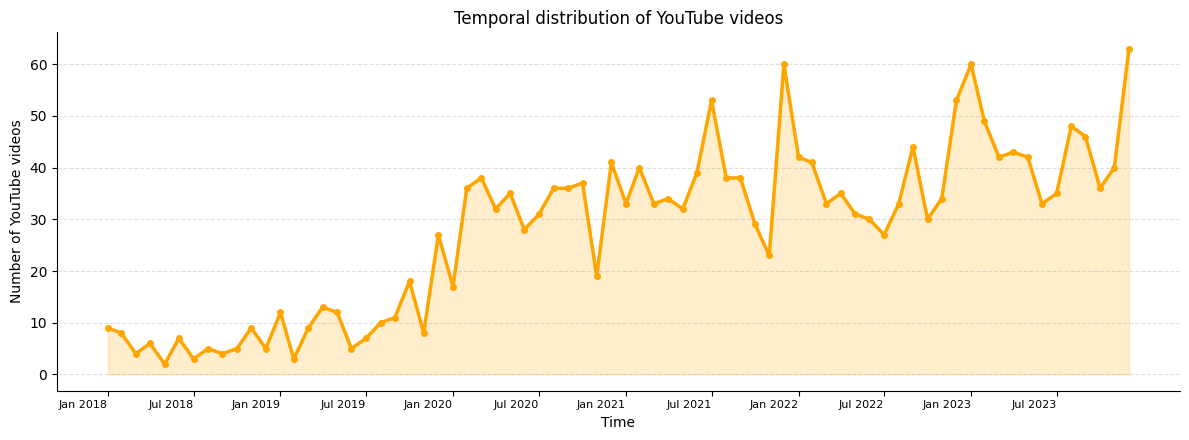

In [ ]:
youtube_temporal = df_youtube_cleaned[['video_id', 'datetime']].copy()
youtube_temporal['datetime'] = pd.to_datetime(youtube_temporal['datetime'], errors='coerce')
youtube_temporal = youtube_temporal.dropna(subset=['datetime']).drop_duplicates(subset='video_id')


monthly_videos = (
    youtube_temporal
    .set_index('datetime')
    .resample('ME')['video_id']
    .nunique()
    .rename('video_count')
    .reset_index()
 )

tick_data = monthly_videos[monthly_videos['datetime'].dt.month.isin([1, 7])].copy()
tick_labels = (
    tick_data['datetime'].dt.strftime('%b %Y')
 )

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(
    monthly_videos['datetime'],
    monthly_videos['video_count'],
    color='orange',
    linewidth=2.5,
    marker='o',
    markersize=4,
 )

ax.fill_between(
    monthly_videos['datetime'],
    monthly_videos['video_count'],
    color='orange',
    alpha=0.2,
 )

ax.set_xticks(tick_data['datetime'])
ax.set_xticklabels(tick_labels, rotation=0, ha='right', fontsize=8)
ax.set_xlabel('Time')
ax.set_ylabel('Number of YouTube videos')
ax.set_title('Temporal distribution of YouTube videos')
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()

# RQ1: visitor groups by demographics

## Gender distribution

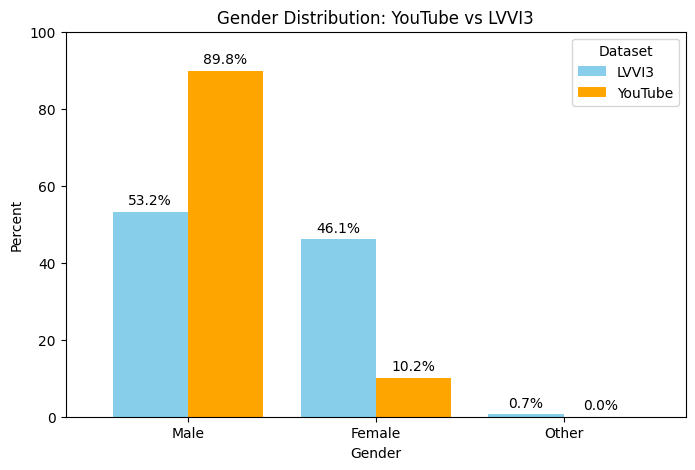

In [ ]:
gender_compare = pd.concat(
    [
        df_channel['gender'].dropna().rename('gender').to_frame().assign(dataset='YouTube'),
        df_lvvi3['gender'].dropna().rename('gender').to_frame().assign(dataset='LVVI3'),
    ],
    ignore_index=True,
 )

gender_percent = (
    gender_compare.groupby(['dataset', 'gender']).size()
    .groupby(level=0)
    .transform(lambda counts: counts / counts.sum() * 100)
    .rename('percent')
    .reset_index()
 )

gender_order = [
    gender
    for gender in ['Male', 'Female', 'Other']
    if gender in gender_percent['gender'].values
 ]

dataset_order = ['LVVI3', 'YouTube']

gender_pivot = (
    gender_percent.pivot(index='gender', columns='dataset', values='percent')
    .reindex(index=gender_order, columns=dataset_order)
    .fillna(0)
 )

ax = gender_pivot.plot(
    kind='bar',
    figsize=(8, 5),
    width=0.8,
    color=['skyblue', 'orange'],
)
ax.set_xlabel('Gender')
ax.set_ylabel('Percent')
ax.set_title('Gender Distribution: YouTube vs LVVI3')
ax.legend(title='Dataset')
ax.set_ylim(0, max(100, gender_pivot.max().max() + 5))
ax.tick_params(axis='x', rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

## Age distribution

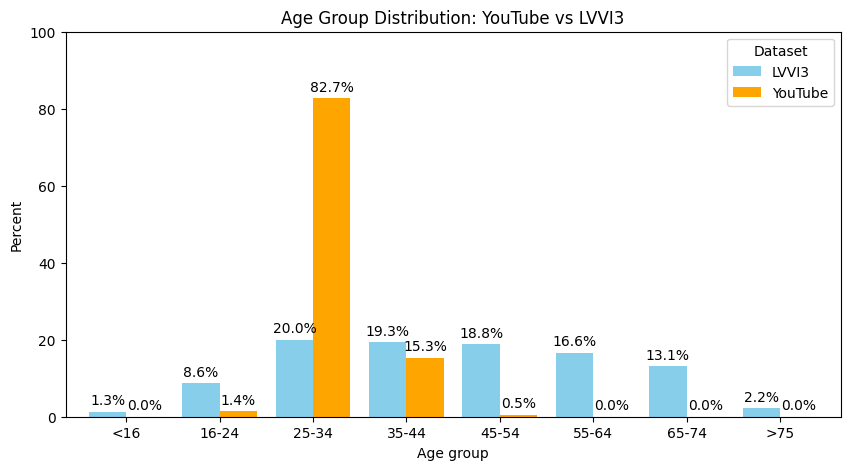

In [ ]:
age_labels = ['<16', '16-24', '25-34', '35-44', '45-54', '55-64', '65-74', '>75']

def normalize_age_group(value):
    if pd.isna(value):
        return pd.NA

    if isinstance(value, (int, float)) and not pd.isna(value):
        return pd.cut(
            pd.Series([value]),
            bins=[0, 16, 25, 35, 45, 55, 65, 75, 101],
            labels=age_labels,
            right=False,
        ).iloc[0]

    value = str(value).strip()
    value = value.replace('–', '-').replace('—', '-').replace('−', '-')

    age_map = {
        '<16': '<16',
        'under 16': '<16',
        '0-15': '<16',
        '16-24': '16-24',
        '15-24': '16-24',
        '25-34': '25-34',
        '25-44': '25-34',
        '35-44': '35-44',
        '45-54': '45-54',
        '45-64': '45-54',
        '55-64': '55-64',
        '65-74': '65-74',
        '65+': '65-74',
        '75+': '>75',
        '>75': '>75',
    }

    return age_map.get(value, value)

youtube_age = df_channel['age_group'].astype('string').rename('age_group').to_frame()
youtube_age['dataset'] = 'YouTube'

lvvi3_age = df_lvvi3['age'].apply(normalize_age_group).astype('string').rename('age_group').to_frame()
lvvi3_age['dataset'] = 'LVVI3'

age_compare = pd.concat([youtube_age, lvvi3_age], ignore_index=True).dropna(subset=['age_group'])

age_percent = (
    age_compare.groupby(['dataset', 'age_group']).size()
    .groupby(level=0)
    .transform(lambda counts: counts / counts.sum() * 100)
    .rename('percent')
    .reset_index()
 )

age_order = [label for label in age_labels if label in age_percent['age_group'].values]
age_order += [
    label
    for label in age_percent['age_group'].unique()
    if label not in age_order
]

dataset_order = ['LVVI3', 'YouTube']

age_pivot = (
    age_percent.pivot(index='age_group', columns='dataset', values='percent')
    .reindex(index=age_order, columns=dataset_order)
    .fillna(0)
 )

ax = age_pivot.plot(
    kind='bar',
    figsize=(10, 5),
    width=0.8,
    color=['skyblue', 'orange'],
)
ax.set_xlabel('Age group')
ax.set_ylabel('Percent')
ax.set_title('Age Group Distribution: YouTube vs LVVI3')
ax.legend(title='Dataset')
ax.tick_params(axis='x', rotation=0)
ax.set_ylim(0, max(100, age_pivot.max().max() + 5))

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

## Statistical analysis

In [37]:
from scipy.stats import chi2_contingency


def run_chi_square_test(data, category_col, category_order=None, dataset_col='dataset'):
    contingency = pd.crosstab(data[category_col], data[dataset_col])

    if category_order is not None:
        contingency = contingency.reindex(category_order).dropna(how='all').fillna(0)

    contingency = contingency.loc[contingency.sum(axis=1) > 0, contingency.sum(axis=0) > 0].astype(int)

    chi2, p_value, dof, expected = chi2_contingency(contingency)
    n = contingency.to_numpy().sum()
    min_dim = min(contingency.shape) - 1
    cramers_v = (chi2 / (n * min_dim)) ** 0.5 if min_dim > 0 else pd.NA

    expected_df = pd.DataFrame(expected, index=contingency.index, columns=contingency.columns)
    min_expected = expected_df.min().min()
    expected_cells_lt_5 = int((expected_df < 5).sum().sum())

    result = {
        'comparison': f'{category_col} vs {dataset_col}',
        'chi2': chi2,
        'dof': dof,
        'p_value': p_value,
        'sample_size': n,
        'cramers_v': cramers_v,
        'min_expected_count': min_expected,
        'expected_cells_lt_5': expected_cells_lt_5,
        'significant_at_0_05': p_value < 0.05,
        'assumption_flag': expected_cells_lt_5 > 0,
    }

    return contingency, expected_df, result


gender_contingency, gender_expected, gender_result = run_chi_square_test(
    gender_compare.dropna(subset=['gender']),
    'gender',
    category_order=gender_order,
)

age_contingency, age_expected, age_result = run_chi_square_test(
    age_compare.dropna(subset=['age_group']),
    'age_group',
    category_order=age_order,
)

chi_square_results = pd.DataFrame([gender_result, age_result])
display_columns = [
    'comparison',
    'chi2',
    'dof',
    'p_value',
    'sample_size',
    'cramers_v',
    'min_expected_count',
    'expected_cells_lt_5',
    'significant_at_0_05',
    'assumption_flag',
]

stats_summary = chi_square_results[display_columns].copy()
stats_summary['chi2'] = stats_summary['chi2'].map(lambda value: f'{value:.3f}')
stats_summary['p_value'] = stats_summary['p_value'].map(lambda value: f'{value:.4g}')
stats_summary['cramers_v'] = stats_summary['cramers_v'].map(
    lambda value: f'{value:.3f}' if pd.notna(value) else value
)
stats_summary['min_expected_count'] = stats_summary['min_expected_count'].map(lambda value: f'{value:.2f}')

print('Observed counts: gender by dataset')
display(gender_contingency)
print('Expected counts under independence: gender by dataset')
display(gender_expected.round(2))

print('Observed counts: age group by dataset')
display(age_contingency)
print('Expected counts under independence: age group by dataset')
display(age_expected.round(2))

print('Chi-square test summary')
display(stats_summary)

print('Note: assumption_flag = True means at least one expected cell count is below 5, so interpret the chi-square result with caution for sparse categories.')

Observed counts: gender by dataset


dataset,LVVI3,YouTube
gender,,
Male,240,873
Female,208,99
Other,3,0


Expected counts under independence: gender by dataset


dataset,LVVI3,YouTube
gender,,
Male,352.75,760.25
Female,97.30,209.70
Other,0.95,2.05


Observed counts: age group by dataset


...

Expected counts under independence: age group by dataset


dataset,LVVI3,YouTube
age_group,,
<16,1.90,4.10
16-24,16.80,36.20
25-34,283.34,610.66
35-44,74.80,161.20
45-54,28.52,61.48
55-64,23.77,51.23
65-74,18.70,40.30
>75,3.17,6.83


Chi-square test summary


,comparison,chi2,dof,p_value,sample_size,cramers_v,min_expected_count,expected_cells_lt_5,significant_at_0_05,assumption_flag
0,gender vs dataset,243.612,2,1.26e-53,1423,0.414,0.95,2,True,True
1,age_group vs dataset,726.001,7,1.707e-152,1423,0.714,1.90,3,True,True


Note: assumption_flag = True means at least one expected cell count is below 5, so interpret the chi-square result with caution for sparse categories.


# RQ2: activity popularity

## Activity popularity

In [ ]:
ls_lvvi3_activity = df_lvvi3['activity'].dropna().unique().tolist()

df_youtube[~df_youtube['activity'].isin(ls_lvvi3_activity)]['activity'].value_counts()

activity
Husky safari                158
Sledding                     79
Treasure hunting             71
Reindeer safari              55
Sauna                        39
Flying a drone               31
Northern lights watching     21
Horseback riding             16
Plant                        14
Grilling                     13
Diving                       13
Snowkiting                   11
Bushcraft                     5
Snowsurfing                   5
Snowmobile safari             5
Flying a kite                 5
Paragliding                   4
Acroyoga                      2
Motorbike riding              1
Abseiling                     1
Polar plunge                  1
Rollerblading                 1
Name: count, dtype: int64

In [ ]:
df_youtube['activity'].value_counts()

activity
Walking                                                        969
Camping                                                        467
Staying overnight in a tent, lodge, etc. in natural terrain    446
Picnicking                                                     322
Staying in a summer cottage, farm, holiday home                266
Skiing                                                         264
Nature observation                                             254
Boating                                                        247
Cycling                                                        235
Nature photography                                             231
Outdoor activities with children                               195
Fishing                                                        171
Snowmobiling                                                   167
Husky safari                                                   158
Travelling or staying in a caravan or camper         

### Activity rank

In [ ]:
# Get counts
youtube_counts = df_youtube['activity'].value_counts()
lvvi3_counts = df_lvvi3['activity'].value_counts()

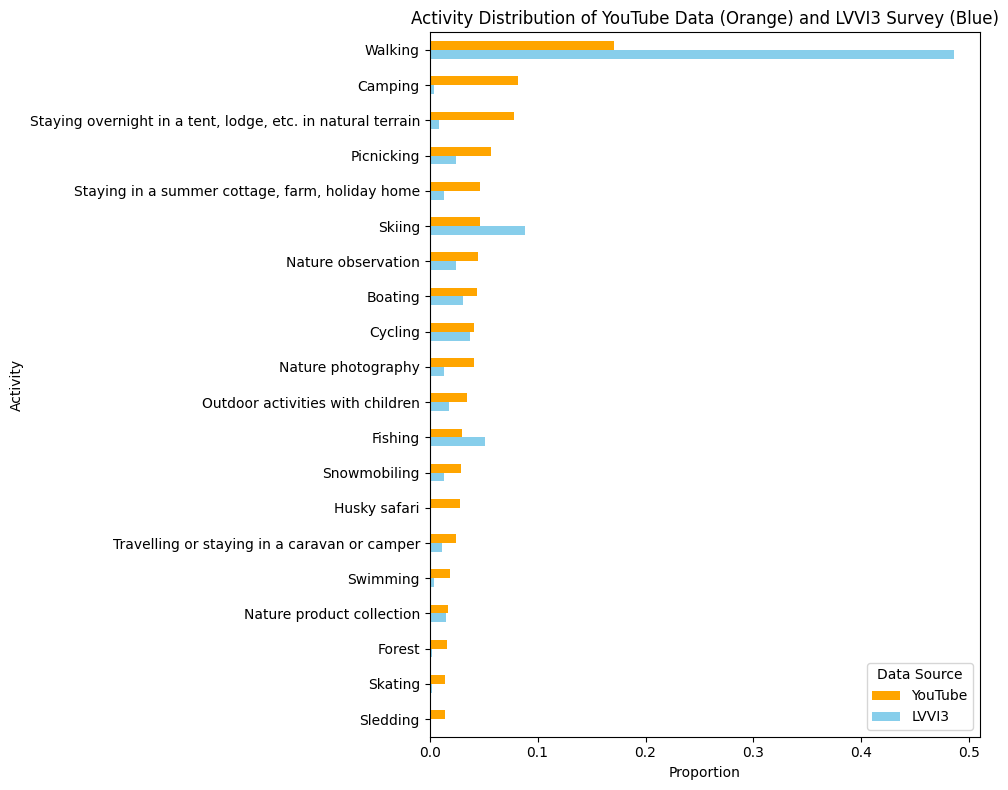

In [ ]:
# Combine counts
combined = pd.DataFrame({
    'YouTube': youtube_counts,
    'LVVI3': lvvi3_counts,
}).fillna(0)

# Normalize
combined = combined / combined.sum()

# Sort by YouTube
combined = combined.sort_values('YouTube', ascending=True).tail(20)

# Reorder columns so YouTube is ABOVE
combined = combined[['LVVI3', 'YouTube']]

# Plot
ax = combined.plot(
    kind='barh',
    figsize=(10, 8),
    color=['skyblue', 'orange']
)

plt.title('Activity Distribution of YouTube Data (Orange) and LVVI3 Survey (Blue)')
plt.xlabel('Proportion')
plt.ylabel('Activity')

# --- legend ---
handles, labels = ax.get_legend_handles_labels()
order = [1, 0]

plt.legend(
    [handles[i] for i in order],
    [labels[i] for i in order],
    title='Data Source'
)

plt.tight_layout()
plt.show()

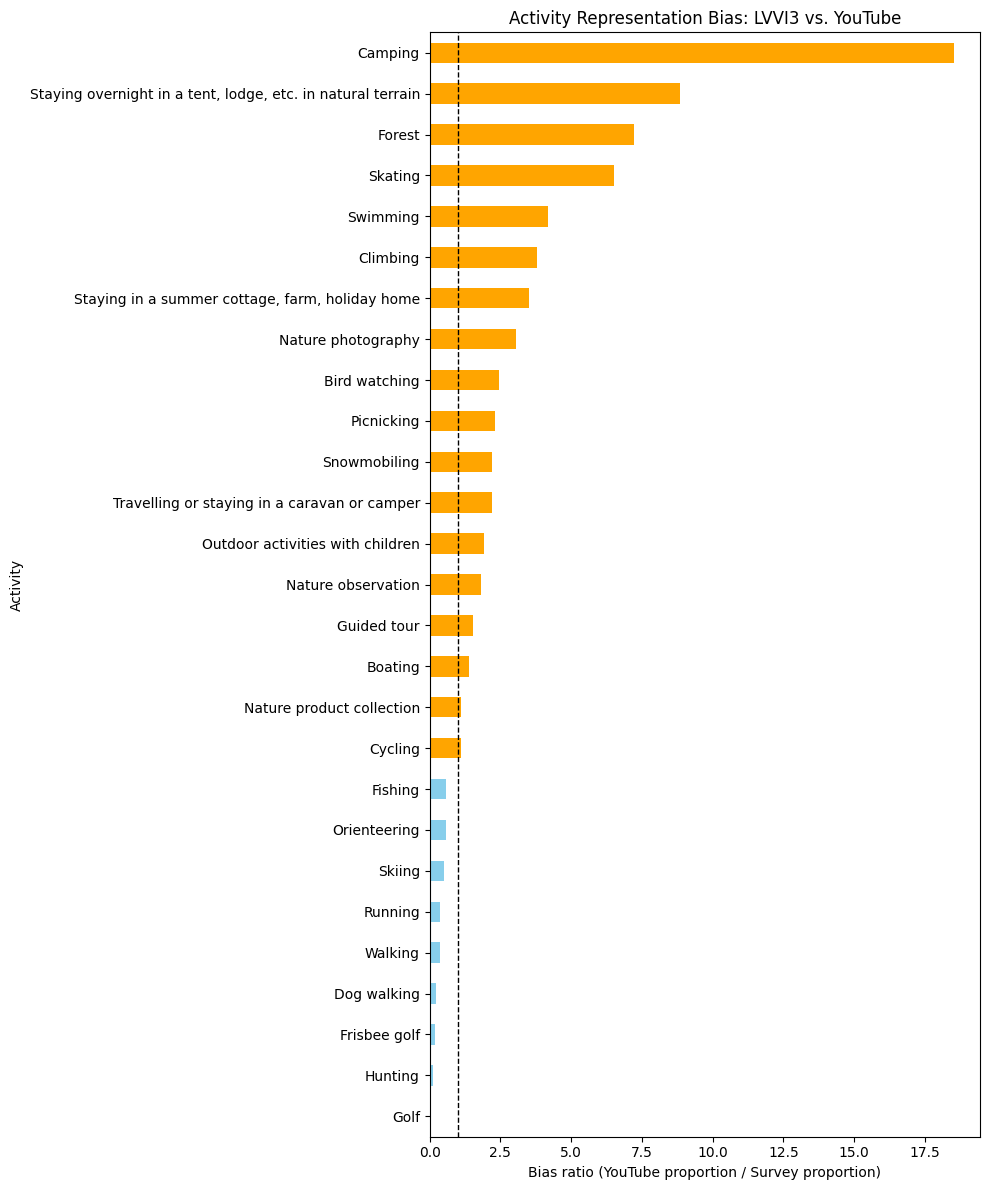

In [ ]:
df_bias = pd.DataFrame({
    'YouTube_count': youtube_counts,
    'LVVI3_count': lvvi3_counts,
}).fillna(0)

df_bias['YouTube_prop'] = df_bias['YouTube_count'] / df_bias['YouTube_count'].sum()
df_bias['LVVI3_prop'] = df_bias['LVVI3_count'] / df_bias['LVVI3_count'].sum()
df_bias['bias'] = df_bias['YouTube_prop'] / df_bias['LVVI3_prop'].replace(0, pd.NA)
df_bias = df_bias.dropna(subset=['bias']).sort_values('bias')

colors = np.where(df_bias['bias'] > 1, 'orange', 'skyblue')

ax = df_bias['bias'].plot(
    kind='barh',
    figsize=(10, 12),
    color=colors,
 )
ax.axvline(1, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Bias ratio (YouTube proportion / Survey proportion)')
ax.set_ylabel('Activity')
ax.set_title('Activity Representation Bias: LVVI3 vs. YouTube')
plt.tight_layout()
plt.show()

In [ ]:
# Convert to ranks
youtube_rank = youtube_counts.rank(ascending=False, method='min')
lvvi3_rank = lvvi3_counts.rank(ascending=False, method='min')

# Combine
rank_df = pd.DataFrame({
    'YouTube': youtube_rank,
    'LVVI3': lvvi3_rank
}).dropna()

# Keep top N (based on YouTube for consistency)
rank_df = rank_df.sort_values('YouTube').head(50)

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


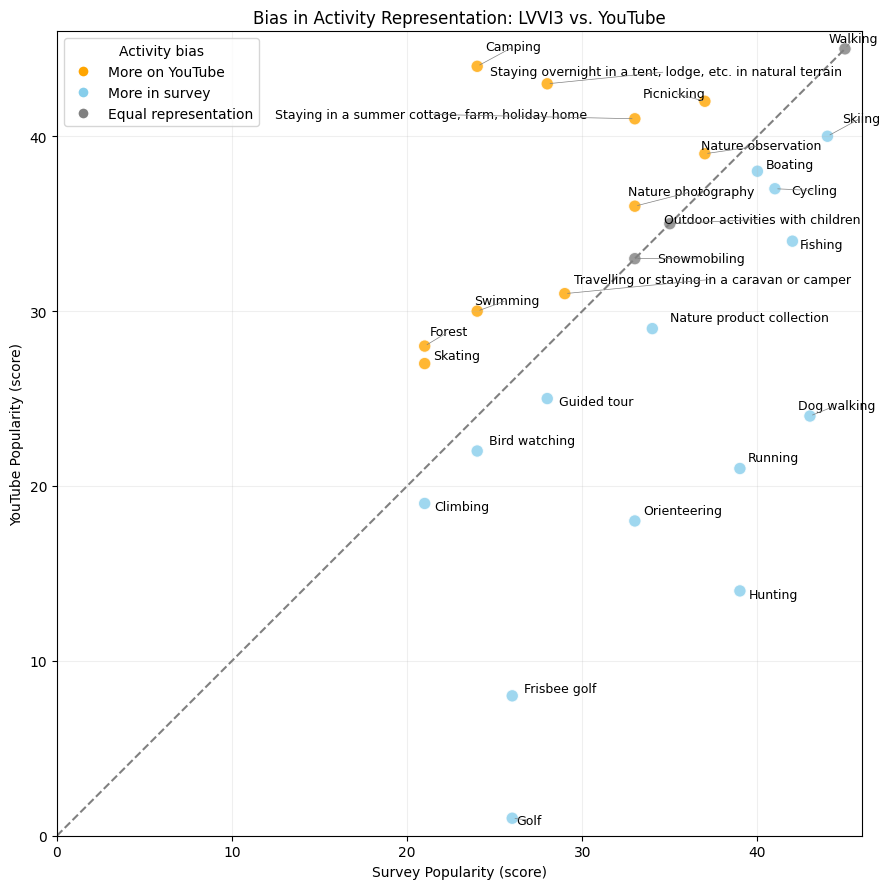

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from adjustText import adjust_text
from matplotlib.lines import Line2D

plt.figure(figsize=(9, 9))

# --- Convert rank -> score (higher = more popular) ---
max_rank = int(rank_df[['LVVI3', 'YouTube']].max().max())

rank_df['LVVI3_score'] = max_rank + 1 - rank_df['LVVI3']
rank_df['YouTube_score'] = max_rank + 1 - rank_df['YouTube']

# --- Compute difference ---
rank_df['diff'] = rank_df['YouTube_score'] - rank_df['LVVI3_score']

# --- Color by bias ---
colors = np.where(
    rank_df['diff'] > 0,
    'orange',
    np.where(rank_df['diff'] < 0, 'skyblue', 'gray'),
)

# --- Scatter ---
plt.scatter(
    rank_df['LVVI3_score'],
    rank_df['YouTube_score'],
    c=colors,
    alpha=0.8,
    s=80,
    edgecolor='white',
    linewidth=0.8,
 )

# --- Diagonal reference line ---
max_score = rank_df[['LVVI3_score', 'YouTube_score']].max().max()
plt.plot([0, max_score], [0, max_score], linestyle='--', color='gray')

texts = []
for activity in rank_df.index:
    x = rank_df.loc[activity, 'LVVI3_score']
    y = rank_df.loc[activity, 'YouTube_score']
    texts.append(plt.text(x, y, activity, fontsize=9))

adjust_text(
    texts,
    arrowprops=dict(arrowstyle='-', color='gray', lw=0.5),
    expand_points=(1.2, 1.2),
)

# Set the axis limits to start at 0
plt.xlim(0, max_score + 1)
plt.ylim(0, max_score + 1)

# --- Labels & title ---
plt.xlabel('Survey Popularity (score)')
plt.ylabel('YouTube Popularity (score)')
plt.title('Bias in Activity Representation: LVVI3 vs. YouTube')

# --- Legend ---
legend_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='orange', markersize=8, label='More on YouTube'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='skyblue', markersize=8, label='More in survey'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', markersize=8, label='Equal representation'),
]
plt.legend(handles=legend_handles, title='Activity bias')

# --- Clean look ---
plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()

In [38]:
from scipy.stats import pearsonr, spearmanr

# Rebuild the rank table used in the scatter plot so the analysis matches the plotted activities.
youtube_rank = youtube_counts.rank(ascending=False, method='min')
lvvi3_rank = lvvi3_counts.rank(ascending=False, method='min')

rank_compare = pd.DataFrame({
    'YouTube_rank': youtube_rank,
    'LVVI3_rank': lvvi3_rank,
}).dropna()
rank_compare = rank_compare.sort_values('YouTube_rank').head(50)

# Build aligned activity-count data for the same plotted activities.
count_compare = pd.DataFrame({
    'YouTube_count': youtube_counts,
    'LVVI3_count': lvvi3_counts,
}).loc[rank_compare.index].copy()
count_compare['YouTube_log_count'] = np.log1p(count_compare['YouTube_count'])
count_compare['LVVI3_log_count'] = np.log1p(count_compare['LVVI3_count'])

spearman_stat, spearman_p = spearmanr(
    rank_compare['LVVI3_rank'],
    rank_compare['YouTube_rank'],
)
pearson_stat, pearson_p = pearsonr(
    count_compare['LVVI3_log_count'],
    count_compare['YouTube_log_count'],
)

test_outputs = [
    {
        'analysis': 'Spearman correlation of activity rank',
        'variables': 'LVVI3 rank vs YouTube rank',
        'sample_size': len(rank_compare),
        'statistic': spearman_stat,
        'p_value': spearman_p,
    },
    {
        'analysis': 'Pearson correlation of log-transformed activity count',
        'variables': 'log1p(LVVI3 count) vs log1p(YouTube count)',
        'sample_size': len(count_compare),
        'statistic': pearson_stat,
        'p_value': pearson_p,
    },
]

activity_correlation_results = pd.DataFrame(test_outputs)
activity_correlation_results['statistic'] = activity_correlation_results['statistic'].map(lambda value: f'{value:.3f}')
activity_correlation_results['p_value'] = activity_correlation_results['p_value'].map(lambda value: f'{value:.4g}')

print('Activity correlation analysis for the plotted cross-dataset scatter data')
display(activity_correlation_results)

print('Rank comparison table used in the Spearman test')
display(rank_compare.head(10))

print('Count comparison table used in the Pearson test (log1p transformed)')
display(count_compare.head(10))

Activity correlation analysis for the plotted cross-dataset scatter data


,analysis,variables,sample_size,statistic,p_value
0,Spearman correlation of activity rank,LVVI3 rank vs YouTube rank,27,0.343,0.08011
1,Pearson correlation of log-transformed activit...,log1p(LVVI3 count) vs log1p(YouTube count),27,0.407,0.03531


Rank comparison table used in the Spearman test


,YouTube_rank,LVVI3_rank
activity,,
Walking,1.0,1.0
Camping,2.0,22.0
"Staying overnight in a tent, lodge, etc. in natural terrain",3.0,18.0
Picnicking,4.0,9.0
"Staying in a summer cottage, farm, holiday home",5.0,13.0
Skiing,6.0,2.0
Nature observation,7.0,9.0
Boating,8.0,6.0
Cycling,9.0,5.0


Count comparison table used in the Pearson test (log1p transformed)


,YouTube_count,LVVI3_count,YouTube_log_count,LVVI3_log_count
activity,,,,
Walking,969,219.0,6.877296,5.393628
Camping,467,2.0,6.148468,1.098612
"Staying overnight in a tent, lodge, etc. in natural terrain",446,4.0,6.102559,1.609438
Picnicking,322,11.0,5.777652,2.484907
"Staying in a summer cottage, farm, holiday home",266,6.0,5.587249,1.945910
Skiing,264,40.0,5.579730,3.713572
Nature observation,254,11.0,5.541264,2.484907
Boating,247,14.0,5.513429,2.708050
Cycling,235,17.0,5.463832,2.890372


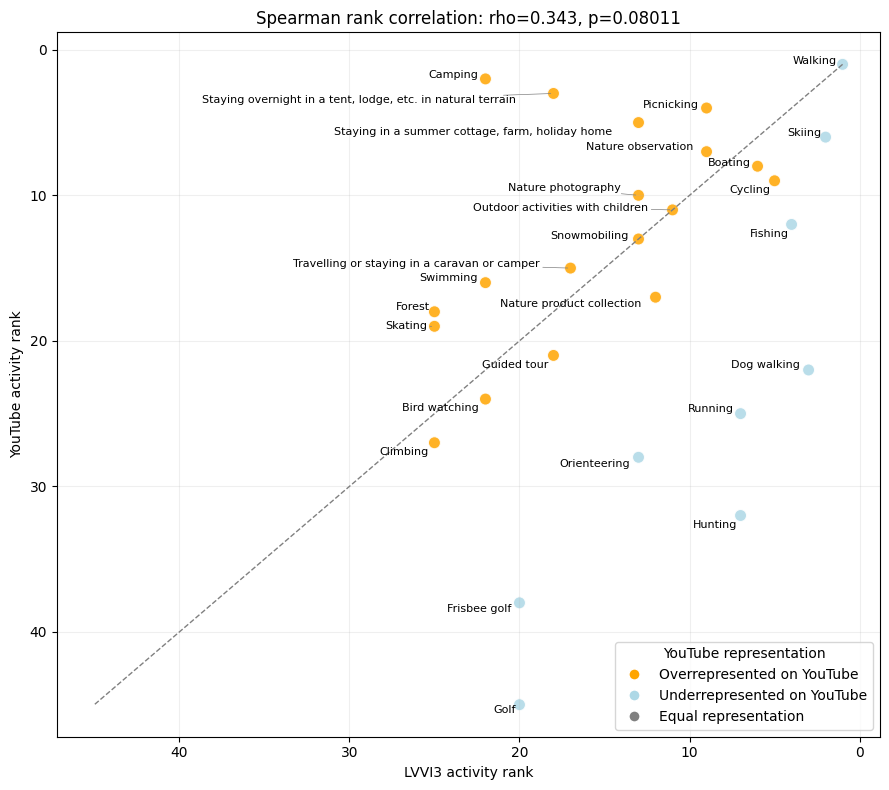

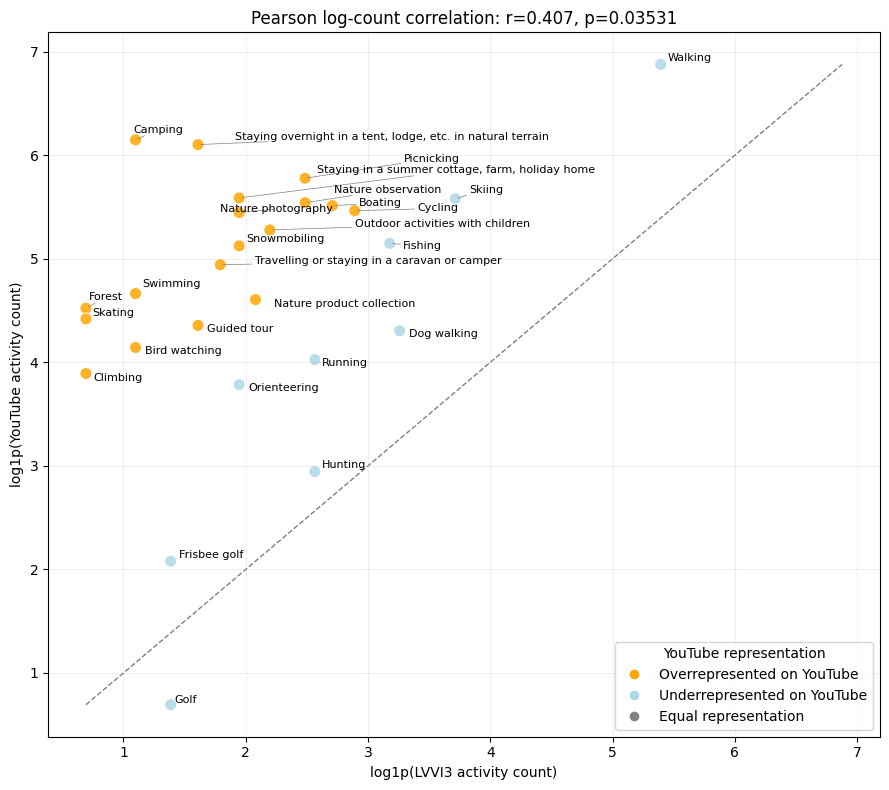

In [40]:
from matplotlib.lines import Line2D

activity_bias_status = df_bias[['bias']].copy()
activity_bias_status['representation'] = np.where(
    activity_bias_status['bias'] > 1,
    'overrepresented',
    np.where(activity_bias_status['bias'] < 1, 'underrepresented', 'balanced'),
)

rank_plot = rank_compare.merge(
    activity_bias_status[['representation']],
    left_index=True,
    right_index=True,
    how='left',
)
rank_plot['representation'] = rank_plot['representation'].fillna('balanced')
rank_plot['point_color'] = rank_plot['representation'].map(
    {
        'overrepresented': 'orange',
        'underrepresented': 'lightblue',
        'balanced': 'gray',
    }
)

count_plot = count_compare.merge(
    activity_bias_status[['representation']],
    left_index=True,
    right_index=True,
    how='left',
)
count_plot['representation'] = count_plot['representation'].fillna('balanced')
count_plot['point_color'] = count_plot['representation'].map(
    {
        'overrepresented': 'orange',
        'underrepresented': 'lightblue',
        'balanced': 'gray',
    }
)

legend_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='orange', markersize=8, label='Overrepresented on YouTube'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='lightblue', markersize=8, label='Underrepresented on YouTube'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', markersize=8, label='Equal representation'),
]

# Scatter plot for Spearman rank correlation
fig, spearman_ax = plt.subplots(figsize=(9, 8))
spearman_ax.scatter(
    rank_plot['LVVI3_rank'],
    rank_plot['YouTube_rank'],
    c=rank_plot['point_color'],
    alpha=0.85,
    s=75,
    edgecolor='white',
    linewidth=0.8,
)

rank_min = min(rank_plot['LVVI3_rank'].min(), rank_plot['YouTube_rank'].min())
rank_max = max(rank_plot['LVVI3_rank'].max(), rank_plot['YouTube_rank'].max())
spearman_ax.plot([rank_min, rank_max], [rank_min, rank_max], linestyle='--', color='gray', linewidth=1)

rank_texts = []
for activity in rank_plot.index:
    rank_texts.append(
        spearman_ax.text(
            rank_plot.loc[activity, 'LVVI3_rank'],
            rank_plot.loc[activity, 'YouTube_rank'],
            activity,
            fontsize=8,
        )
    )

adjust_text(
    rank_texts,
    ax=spearman_ax,
    arrowprops=dict(arrowstyle='-', color='gray', lw=0.5),
)

spearman_ax.set_xlabel('LVVI3 activity rank')
spearman_ax.set_ylabel('YouTube activity rank')
spearman_ax.set_title(f'Spearman rank correlation: rho={spearman_stat:.3f}, p={spearman_p:.4g}')
spearman_ax.grid(alpha=0.2)
spearman_ax.legend(handles=legend_handles, title='YouTube representation')
spearman_ax.invert_xaxis()
spearman_ax.invert_yaxis()
plt.tight_layout()
plt.show()

# Scatter plot for Pearson correlation on log-transformed counts
fig, pearson_ax = plt.subplots(figsize=(9, 8))
pearson_ax.scatter(
    count_plot['LVVI3_log_count'],
    count_plot['YouTube_log_count'],
    c=count_plot['point_color'],
    alpha=0.85,
    s=75,
    edgecolor='white',
    linewidth=0.8,
)

log_min = min(count_plot['LVVI3_log_count'].min(), count_plot['YouTube_log_count'].min())
log_max = max(count_plot['LVVI3_log_count'].max(), count_plot['YouTube_log_count'].max())
pearson_ax.plot([log_min, log_max], [log_min, log_max], linestyle='--', color='gray', linewidth=1)

pearson_texts = []
for activity in count_plot.index:
    pearson_texts.append(
        pearson_ax.text(
            count_plot.loc[activity, 'LVVI3_log_count'],
            count_plot.loc[activity, 'YouTube_log_count'],
            activity,
            fontsize=8,
        )
    )

adjust_text(
    pearson_texts,
    ax=pearson_ax,
    arrowprops=dict(arrowstyle='-', color='gray', lw=0.5),
)

pearson_ax.set_xlabel('log1p(LVVI3 activity count)')
pearson_ax.set_ylabel('log1p(YouTube activity count)')
pearson_ax.set_title(f'Pearson log-count correlation: r={pearson_stat:.3f}, p={pearson_p:.4g}')
pearson_ax.grid(alpha=0.2)
pearson_ax.legend(handles=legend_handles, title='YouTube representation')
plt.tight_layout()
plt.show()

### Activity distribution across gender and age

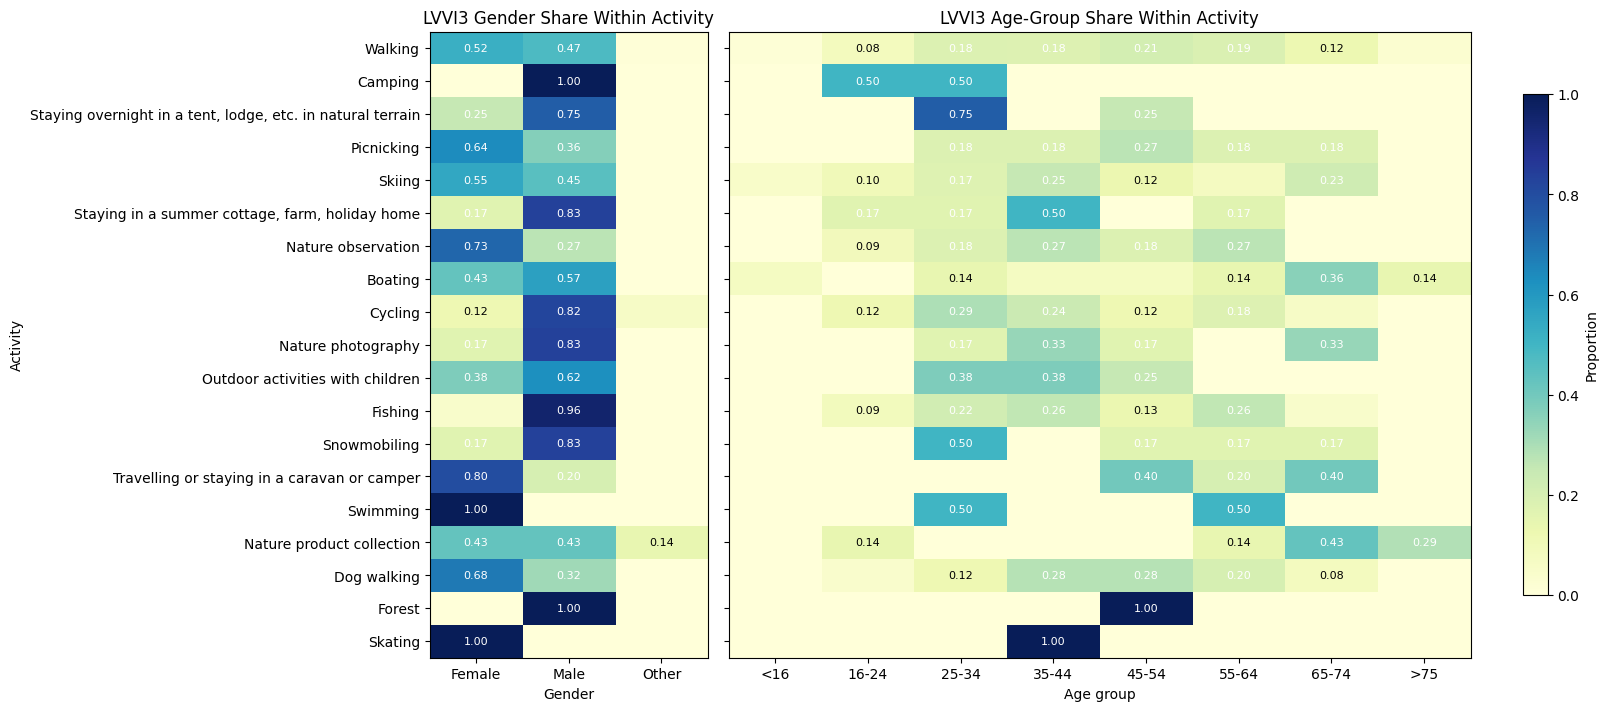

In [ ]:
def annotate_heatmap(ax, matrix, threshold=0.08):
    for row_index in range(matrix.shape[0]):
        for col_index in range(matrix.shape[1]):
            value = matrix[row_index, col_index]
            if value >= threshold:
                ax.text(
                    col_index,
                    row_index,
                    f'{value:.2f}',
                    ha='center',
                    va='center',
                    color='white' if value >= 0.15 else 'black',
                    fontsize=8,
                )

def build_activity_matrix(df, column, columns=None):
    matrix = pd.crosstab(df['activity'], df[column], normalize='index').reindex(index=activity_order)
    if columns is not None:
        matrix = matrix.reindex(columns=columns)
    return matrix.dropna(how='all').dropna(axis=1, how='all').fillna(0)

def plot_activity_heatmaps(gender_matrix, age_matrix, title_prefix):
    fig_height = max(6, len(activity_order) * 0.35)
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(16, fig_height),
        constrained_layout=True,
        gridspec_kw={'width_ratios': [max(1, gender_matrix.shape[1]), max(1, age_matrix.shape[1])]},
    )

    heatmaps = [
        (axes[0], gender_matrix, f'{title_prefix} Gender Share Within Activity', 'Gender', 'Activity'),
        (axes[1], age_matrix, f'{title_prefix} Age-Group Share Within Activity', 'Age group', ''),
    ]

    for ax, matrix, title, xlabel, ylabel in heatmaps:
        im = ax.imshow(matrix.values, aspect='auto', cmap='YlGnBu', vmin=0, vmax=1)
        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.set_xticks(range(matrix.shape[1]))
        ax.set_xticklabels(matrix.columns, rotation=0)
        ax.set_yticks(range(matrix.shape[0]))
        ax.set_yticklabels(matrix.index if ylabel else [])
        annotate_heatmap(ax, matrix.to_numpy())

    fig.colorbar(im, ax=axes, label='Proportion', shrink=0.8)

lvvi3_activity = df_lvvi3[['activity', 'gender', 'age']].copy()
lvvi3_activity['gender'] = lvvi3_activity['gender'].replace({'Man': 'Male', 'Woman': 'Female'})
lvvi3_activity['age_group'] = lvvi3_activity['age'].apply(normalize_age_group).astype('string')
lvvi3_activity = lvvi3_activity.explode('activity')
lvvi3_activity['activity'] = lvvi3_activity['activity'].astype('string').str.strip()
lvvi3_activity = lvvi3_activity[
    lvvi3_activity['activity'].notna()
    & (lvvi3_activity['activity'] != '')
    & lvvi3_activity['gender'].notna()
    & lvvi3_activity['age_group'].notna()
]

youtube_activity_base = df_youtube[['activity']].copy()
youtube_activity_base['activity'] = youtube_activity_base['activity'].astype('string').str.strip()
youtube_activity_base = youtube_activity_base[youtube_activity_base['activity'].notna() & (youtube_activity_base['activity'] != '')]

top_n_activities = 20
activity_order = (
    pd.concat([lvvi3_activity['activity'], youtube_activity_base['activity']], ignore_index=True)
    .value_counts()
    .head(top_n_activities)
    .index.tolist()
 )

gender_activity = build_activity_matrix(lvvi3_activity, 'gender')
age_activity = build_activity_matrix(lvvi3_activity, 'age_group', age_labels)

plot_activity_heatmaps(gender_activity, age_activity, 'LVVI3')

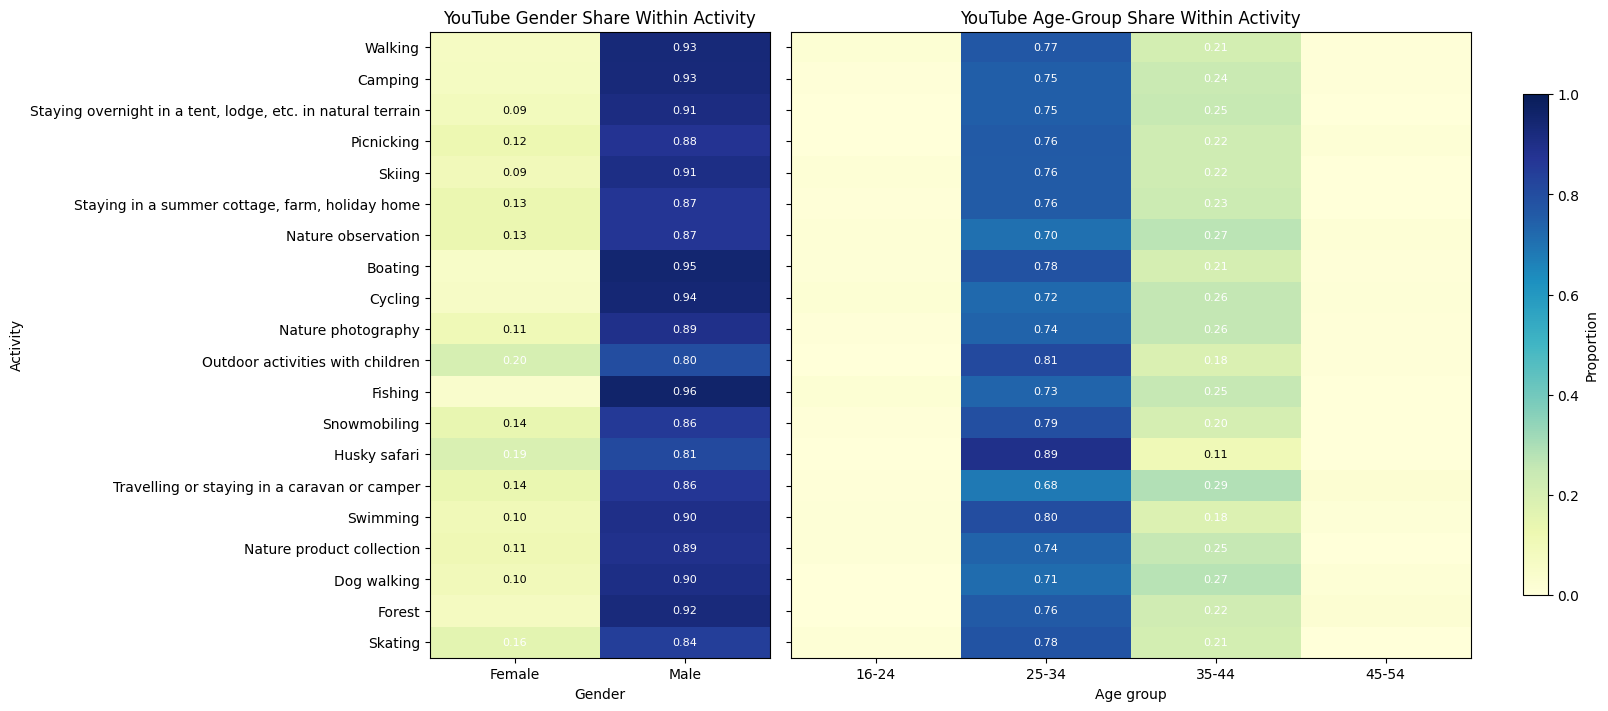

In [ ]:
youtube_activity = df_youtube[['activity', 'gender', 'age_group']].copy()
youtube_activity = youtube_activity.dropna(subset=['activity', 'gender', 'age_group'])
youtube_activity['activity'] = youtube_activity['activity'].astype('string').str.strip()
youtube_activity['gender'] = youtube_activity['gender'].astype('string').str.strip()
youtube_activity['age_group'] = youtube_activity['age_group'].astype('string').str.strip()
youtube_activity = youtube_activity[
    (youtube_activity['activity'] != '')
    & (youtube_activity['gender'] != '')
    & (youtube_activity['age_group'] != '')
]

youtube_gender_activity = build_activity_matrix(youtube_activity, 'gender')
youtube_age_activity = build_activity_matrix(youtube_activity, 'age_group', age_labels)

plot_activity_heatmaps(youtube_gender_activity, youtube_age_activity, 'YouTube')

## Gender and age distribution

In [ ]:
from adjustText import adjust_text
from matplotlib.lines import Line2D

def build_activity_scatter_summary(df, activity_col='activity', top_n=30):
    activity_gender = pd.crosstab(df[activity_col], df['gender']).reindex(columns=['Male', 'Female'], fill_value=0)
    activity_gender['total'] = activity_gender['Male'] + activity_gender['Female']
    activity_gender = activity_gender[activity_gender['total'] > 0].copy()
    activity_gender['male_share'] = activity_gender['Male'] / activity_gender['total']
    activity_gender['female_share'] = activity_gender['Female'] / activity_gender['total']
    activity_gender['gender_balance'] = activity_gender['female_share'] - activity_gender['male_share']

    activity_age = pd.crosstab(df[activity_col], df['age_group']).reindex(columns=age_labels, fill_value=0)
    activity_gender['age_group'] = activity_age.idxmax(axis=1)

    summary = activity_gender.reset_index()[[activity_col, 'total', 'gender_balance', 'age_group']]
    summary = summary.rename(columns={activity_col: 'activity'})
    summary = summary.sort_values('total', ascending=False).head(top_n).copy()

    summary['age_group'] = pd.Categorical(
        summary['age_group'],
        categories=age_labels,
        ordered=True,
    )
    summary = summary.sort_values(['age_group', 'total'], ascending=[True, False])

    age_positions = {age_group: index for index, age_group in enumerate(age_labels)}
    summary['y_position'] = summary['age_group'].map(age_positions).astype(float)

    counts_within_age = summary.groupby('age_group', observed=False).cumcount()
    totals_within_age = summary.groupby('age_group', observed=False)['activity'].transform('count')
    summary['y_offset'] = np.where(
        totals_within_age > 1,
        (counts_within_age - (totals_within_age - 1) / 2) * 0.1,
        0,
    )
    summary['y_plot'] = summary['y_position'] + summary['y_offset']

    return summary

def build_bubble_legend_counts(counts):
    nice_counts = np.array([10, 20, 50, 100, 200, 500, 1000, 2000, 5000])
    min_count = counts.min()
    max_count = counts.max()
    selected = nice_counts[(nice_counts >= min_count) & (nice_counts <= max_count)]

    if len(selected) >= 3:
        middle_index = len(selected) // 2
        return [int(selected[0]), int(selected[middle_index]), int(selected[-1])]

    if len(selected) == 2:
        return [int(selected[0]), int(selected[1])]

    if len(selected) == 1:
        return [int(selected[0])]

    return sorted({
        int(round(min_count, -1)) if min_count >= 10 else int(min_count),
        int(round((min_count + max_count) / 2, -1)) if max_count >= 10 else int((min_count + max_count) / 2),
        int(round(max_count, -1)) if max_count >= 10 else int(max_count),
    })

def compute_bubble_area(counts, area_scale=6, area_power=1.0, min_area=0):
    return np.maximum(min_area, np.power(counts, area_power) * area_scale)

def build_bubble_legend_handles(counts, color, area_scale=6, area_power=1.0, min_area=0):
    legend_counts = build_bubble_legend_counts(counts)
    return [
        Line2D(
            [0], [0],
            marker='o',
            color='w',
            label=str(count_value),
            markerfacecolor=color,
            markeredgecolor='white',
            markeredgewidth=0.8,
            alpha=0.75,
            markersize=max(6, np.sqrt(compute_bubble_area(np.array([count_value]), area_scale, area_power, min_area)[0]) / 2.3),
        )
        for count_value in legend_counts
    ]

def plot_activity_gender_age_scatter(
    summary,
    title,
    color,
    legend_label,
    area_scale=6,
    area_power=1.0,
    min_area=0,
    representation_col=None,
 ):
    fig, ax = plt.subplots(figsize=(13.5, 7.5))
    bubble_area = compute_bubble_area(summary['total'], area_scale, area_power, min_area)

    ax.scatter(
        summary['gender_balance'],
        summary['y_plot'],
        s=bubble_area,
        color=color,
        alpha=0.75,
        edgecolor='white',
        linewidth=0.8,
    )

    if representation_col and representation_col in summary.columns:
        text_color_map = {
            'overrepresented': 'red',
            'underrepresented': 'black',
            'balanced': 'black',
        }
    else:
        text_color_map = {}

    texts = []
    for row in summary.itertuples():
        label_color = text_color_map.get(getattr(row, representation_col), 'black') if representation_col else 'black'
        texts.append(
            ax.text(
                row.gender_balance,
                row.y_plot,
                row.activity,
                fontsize=7,
                ha='left',
                va='center',
                color=label_color,
            )
        )

    adjust_text(
        texts,
        ax=ax,
        arrowprops=dict(arrowstyle='-', color='gray', lw=0.35),
        expand_points=(1.35, 1.5),
        expand_text=(1.2, 1.35),
        force_points=0.8,
        force_text=1.0,
        force_static=0.4,
        only_move={'points': 'y', 'text': 'xy'},
    )

    tick_positions = [-0.8, -0.6, -0.4, -0.2, 0, 0.2, 0.4, 0.6, 0.8]
    tick_labels = [
        '90% male',
        '80% male',
        '70% male',
        '60% male',
        '50 / 50',
        '60% female',
        '70% female',
        '80% female',
        '90% female',
    ]

    size_handles = build_bubble_legend_handles(
        summary['total'],
        color,
        area_scale=area_scale,
        area_power=area_power,
        min_area=min_area,
    )
    point_handle = Line2D(
        [0], [0],
        marker='o',
        color='w',
        label=legend_label,
        markerfacecolor=color,
        markeredgecolor='white',
        markeredgewidth=0.8,
        markersize=9,
        alpha=0.75,
    )

    ax.set_xticks(tick_positions)
    ax.set_xticklabels(tick_labels, rotation=0)
    ax.set_xlim(-1, 1)
    ax.axvline(0, color='gray', linestyle='--', linewidth=1)
    ax.set_yticks(range(len(age_labels)))
    ax.set_yticklabels(age_labels)
    ax.set_ylim(-0.5, len(age_labels) - 0.5)
    ax.set_xlabel('Gender proportion within activity')
    ax.set_ylabel('Most common age group')
    ax.set_title(title)
    ax.grid(axis='x', linestyle='--', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    first_legend = ax.legend(
        handles=[point_handle],
        loc='upper left',
        bbox_to_anchor=(1.02, 1.0),
        frameon=True,
        title='Dataset',
        borderpad=0.8,
    )
    ax.add_artist(first_legend)

    ax.legend(
        handles=size_handles,
        loc='lower left',
        bbox_to_anchor=(1.02, 0.0),
        frameon=True,
        title='Activity count',
        borderpad=0.9,
        labelspacing=1.15,
        handletextpad=1.0,
        borderaxespad=0.0,
    )
    plt.tight_layout(rect=[0, 0, 0.82, 1])

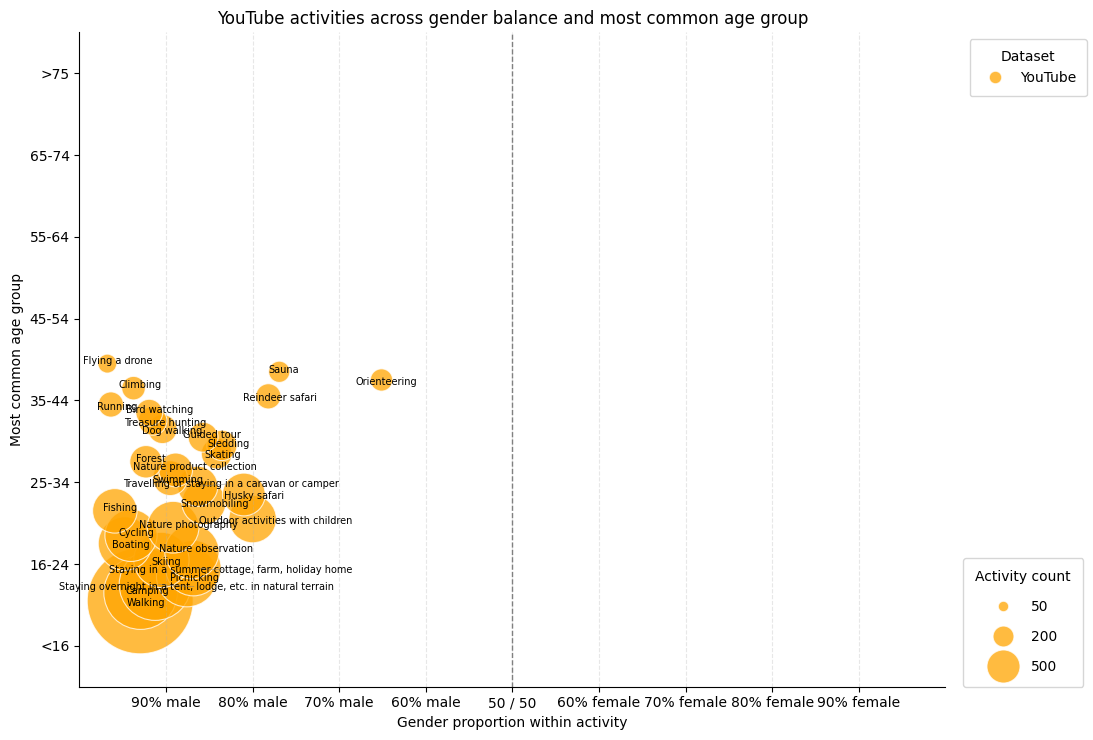

In [ ]:
youtube_scatter = df_youtube[['activity', 'gender', 'age_group']].copy()
youtube_scatter = youtube_scatter.dropna(subset=['activity', 'gender', 'age_group'])
youtube_scatter['activity'] = youtube_scatter['activity'].astype('string').str.strip()
youtube_scatter['gender'] = youtube_scatter['gender'].astype('string').str.strip()
youtube_scatter['age_group'] = youtube_scatter['age_group'].astype('string').str.strip()
youtube_scatter = youtube_scatter[
    (youtube_scatter['activity'] != '')
    & (youtube_scatter['gender'].isin(['Male', 'Female']))
    & (youtube_scatter['age_group'].isin(age_labels))
]

youtube_activity_summary = build_activity_scatter_summary(youtube_scatter)
plot_activity_gender_age_scatter(
    youtube_activity_summary,
    'YouTube activities across gender balance and most common age group',
    'orange',
    'YouTube',
)

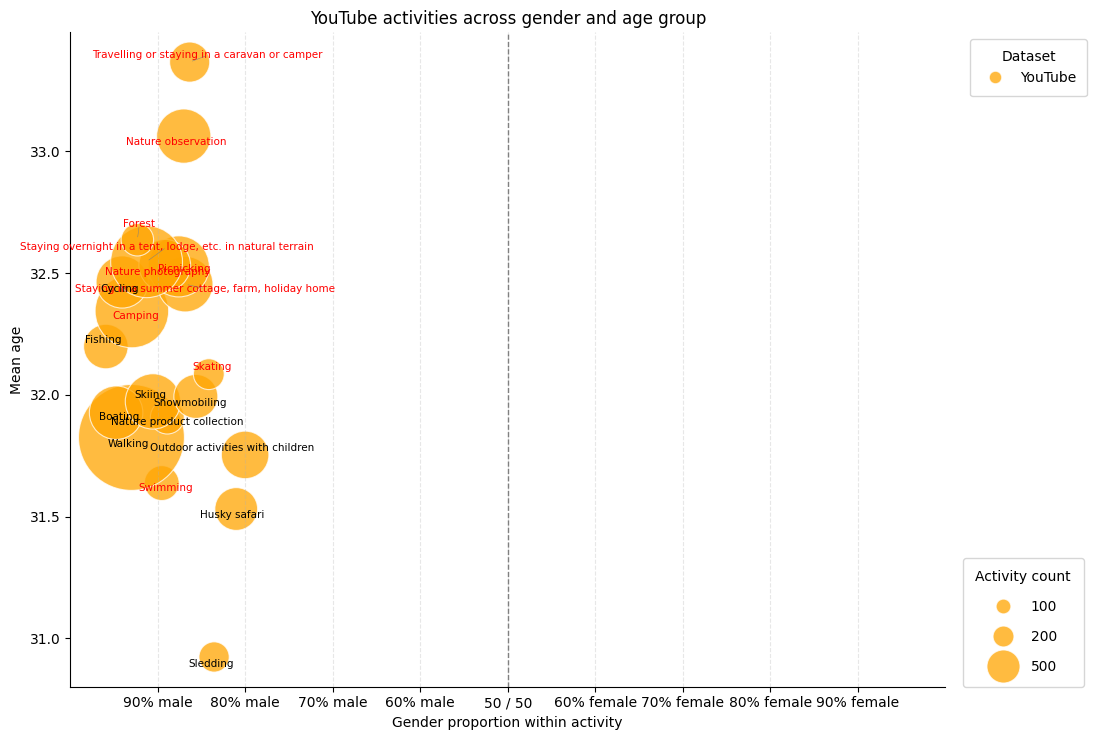

In [42]:
youtube_mean_age_scatter = df_youtube[['activity', 'gender', 'age']].copy()
youtube_mean_age_scatter = youtube_mean_age_scatter.dropna(subset=['activity', 'gender', 'age'])
youtube_mean_age_scatter['activity'] = youtube_mean_age_scatter['activity'].astype('string').str.strip()
youtube_mean_age_scatter['gender'] = youtube_mean_age_scatter['gender'].astype('string').str.strip()
youtube_mean_age_scatter['age'] = pd.to_numeric(youtube_mean_age_scatter['age'], errors='coerce')
youtube_mean_age_scatter = youtube_mean_age_scatter[
    (youtube_mean_age_scatter['activity'] != '')
    & (youtube_mean_age_scatter['gender'].isin(['Male', 'Female']))
    & youtube_mean_age_scatter['age'].notna()
 ]

youtube_mean_age_summary = (
    youtube_mean_age_scatter.groupby('activity').agg(
        male_count=('gender', lambda values: (values == 'Male').sum()),
        female_count=('gender', lambda values: (values == 'Female').sum()),
        mean_age=('age', 'mean'),
    )
 )
youtube_mean_age_summary['total'] = (
    youtube_mean_age_summary['male_count'] + youtube_mean_age_summary['female_count']
 )
youtube_mean_age_summary = youtube_mean_age_summary[youtube_mean_age_summary['total'] > 0].copy()
youtube_mean_age_summary['male_share'] = (
    youtube_mean_age_summary['male_count'] / youtube_mean_age_summary['total']
 )
youtube_mean_age_summary['female_share'] = (
    youtube_mean_age_summary['female_count'] / youtube_mean_age_summary['total']
 )
youtube_mean_age_summary['gender_balance'] = (
    youtube_mean_age_summary['female_share'] - youtube_mean_age_summary['male_share']
 )
youtube_mean_age_summary = (
    youtube_mean_age_summary
    .sort_values('total', ascending=False)
    .head(20)
    .reset_index()
    .sort_values(['mean_age', 'total'], ascending=[True, False])
 )

youtube_score_status = rank_df[['diff']].copy()
youtube_score_status['representation'] = np.where(
    youtube_score_status['diff'] > 0,
    'overrepresented',
    np.where(youtube_score_status['diff'] < 0, 'underrepresented', 'balanced'),
)

youtube_mean_age_summary = youtube_mean_age_summary.merge(
    youtube_score_status[['representation']],
    left_on='activity',
    right_index=True,
    how='left',
)
youtube_mean_age_summary['representation'] = youtube_mean_age_summary['representation'].fillna('balanced')

fig, ax = plt.subplots(figsize=(13.5, 7.5))
ax.scatter(
    youtube_mean_age_summary['gender_balance'],
    youtube_mean_age_summary['mean_age'],
    s=youtube_mean_age_summary['total'] * 6,
    color='orange',
    alpha=0.75,
    edgecolor='white',
    linewidth=0.8,
 )

text_color_map = {
    'overrepresented': 'red',
    'underrepresented': 'black',
    'balanced': 'black',
}

texts = []
for row in youtube_mean_age_summary.itertuples():
    texts.append(
        ax.text(
            row.gender_balance,
            row.mean_age,
            row.activity,
            fontsize=7.5,
            ha='center',
            va='center',
            color=text_color_map.get(row.representation, 'black'),
        )
    )

adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(arrowstyle='-', color='gray', lw=0.35),
    expand_points=(1.35, 1.5),
    expand_text=(1.2, 1.35),
    force_points=0.6,
    force_text=0.8,
    force_static=0.3,
    only_move={'points': 'y', 'text': 'xy'},
)

tick_positions = [-0.8, -0.6, -0.4, -0.2, 0, 0.2, 0.4, 0.6, 0.8]
tick_labels = [
    '90% male',
    '80% male',
    '70% male',
    '60% male',
    '50 / 50',
    '60% female',
    '70% female',
    '80% female',
    '90% female',
]

size_handles = build_bubble_legend_handles(youtube_mean_age_summary['total'], 'orange')
point_handle = Line2D(
    [0], [0],
    marker='o',
    color='w',
    label='YouTube',
    markerfacecolor='orange',
    markeredgecolor='white',
    markeredgewidth=0.8,
    markersize=9,
    alpha=0.75,
)

ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels, rotation=0)
ax.set_xlim(-1, 1)
ax.axvline(0, color='gray', linestyle='--', linewidth=1)
ax.set_xlabel('Gender proportion within activity')
ax.set_ylabel('Mean age')
ax.set_title('YouTube activities across gender and age group')
ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
first_legend = ax.legend(
    handles=[point_handle],
    loc='upper left',
    bbox_to_anchor=(1.02, 1.0),
    frameon=True,
    title='Dataset',
    borderpad=0.8,
 )
ax.add_artist(first_legend)
ax.legend(
    handles=size_handles,
    loc='lower left',
    bbox_to_anchor=(1.02, 0.0),
    frameon=True,
    title='Activity count',
    borderpad=0.9,
    labelspacing=1.15,
    handletextpad=1.0,
    borderaxespad=0.0,
 )
plt.tight_layout(rect=[0, 0, 0.82, 1])
plt.show()

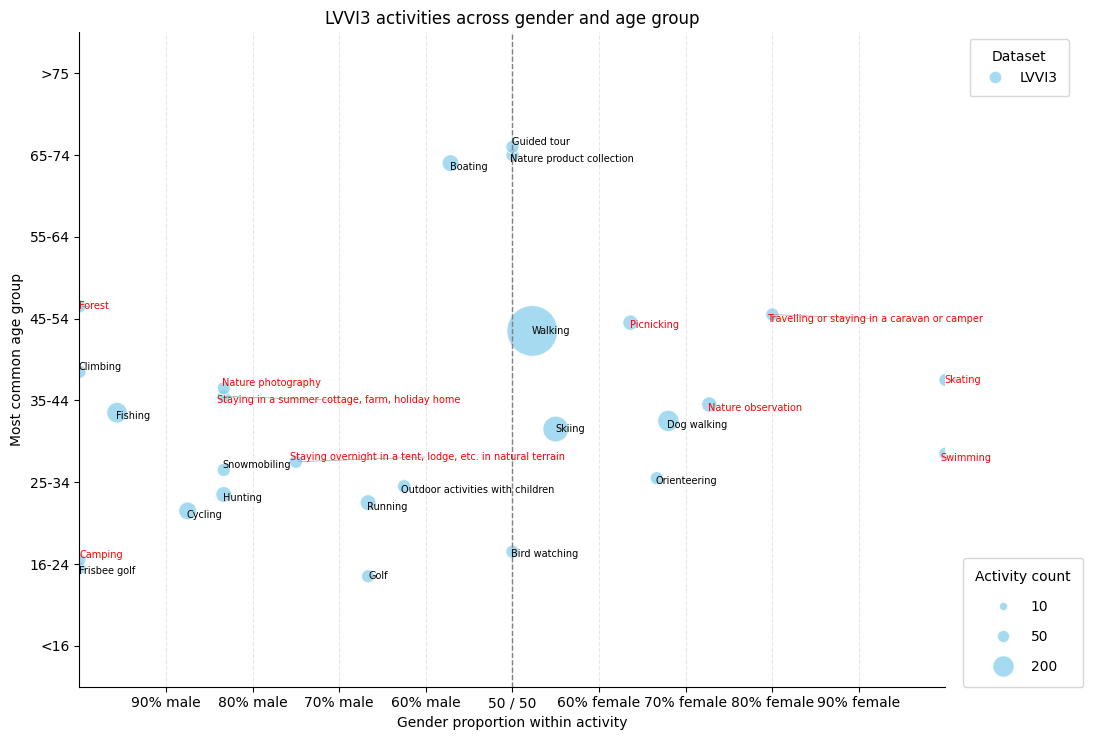

In [41]:
lvvi3_scatter = df_lvvi3[['activity', 'gender', 'age']].copy()
lvvi3_scatter['gender'] = lvvi3_scatter['gender'].replace({'Man': 'Male', 'Woman': 'Female'})
lvvi3_scatter['age_group'] = lvvi3_scatter['age'].apply(normalize_age_group).astype('string')
lvvi3_scatter = lvvi3_scatter.explode('activity')
lvvi3_scatter['activity'] = lvvi3_scatter['activity'].astype('string').str.strip()
lvvi3_scatter['gender'] = lvvi3_scatter['gender'].astype('string').str.strip()
lvvi3_scatter['age_group'] = lvvi3_scatter['age_group'].astype('string').str.strip()
lvvi3_scatter = lvvi3_scatter[
    (lvvi3_scatter['activity'] != '')
    & (lvvi3_scatter['gender'].isin(['Male', 'Female']))
    & (lvvi3_scatter['age_group'].isin(age_labels))
]

lvvi3_activity_summary = build_activity_scatter_summary(lvvi3_scatter)
lvvi3_score_status = rank_df[['diff']].copy()
lvvi3_score_status['representation'] = np.where(
    lvvi3_score_status['diff'] > 0,
    'overrepresented',
    np.where(lvvi3_score_status['diff'] < 0, 'underrepresented', 'balanced'),
)

lvvi3_activity_summary = lvvi3_activity_summary.merge(
    lvvi3_score_status[['representation']],
    left_on='activity',
    right_index=True,
    how='left',
)
lvvi3_activity_summary['representation'] = lvvi3_activity_summary['representation'].fillna('balanced')

plot_activity_gender_age_scatter(
    lvvi3_activity_summary,
    'LVVI3 activities across gender and age group',
    'skyblue',
    'LVVI3',
    area_scale=18,
    area_power=0.8,
    min_area=90,
    representation_col='representation',
)

In [ ]:
df_lvvi3.activity.value_counts()

activity
Walking                                                        219
Skiing                                                          40
Dog walking                                                     25
Fishing                                                         23
Cycling                                                         17
Boating                                                         14
Running                                                         12
Hunting                                                         12
Picnicking                                                      11
Nature observation                                              11
Outdoor activities with children                                 8
Nature product collection                                        7
Staying in a summer cottage, farm, holiday home                  6
Snowmobiling                                                     6
Nature photography                                   

## Statistical analysis

### Gender and age groups comparison

In [ ]:
ls_lvvi3_activity_10 = df_lvvi3.activity.value_counts().head(10).index.tolist()
ls_youtube_activity_10 = df_youtube.activity.value_counts().head(10).index.tolist()
ls_activity_select = list(set(ls_lvvi3_activity_10) | set(ls_youtube_activity_10))

df_lvvi3_select = df_lvvi3[df_lvvi3['activity'].isin(ls_activity_select)].copy()
df_youtube_select = df_youtube[df_youtube['activity'].isin(ls_activity_select)].copy()

In [ ]:
from IPython.display import display
from scipy.stats import chi2_contingency

def prepare_lvvi3_activity_for_test():
    lvvi3_stat = df_lvvi3_select[['activity', 'gender', 'age']].copy()
    lvvi3_stat['gender'] = lvvi3_stat['gender'].replace({'Man': 'Male', 'Woman': 'Female'})
    lvvi3_stat['age_group'] = lvvi3_stat['age'].apply(normalize_age_group).astype('string')
    lvvi3_stat = lvvi3_stat.explode('activity')
    lvvi3_stat['activity'] = lvvi3_stat['activity'].astype('string').str.strip()
    return lvvi3_stat[
        lvvi3_stat['activity'].notna()
        & (lvvi3_stat['activity'] != '')
        & lvvi3_stat['gender'].notna()
        & lvvi3_stat['age_group'].notna()
    ]

def prepare_youtube_activity_for_test():
    youtube_stat = df_youtube_select[['activity', 'gender', 'age_group']].copy()
    youtube_stat = youtube_stat.dropna(subset=['activity', 'gender', 'age_group'])
    youtube_stat['activity'] = youtube_stat['activity'].astype('string').str.strip()
    youtube_stat['gender'] = youtube_stat['gender'].astype('string').str.strip()
    youtube_stat['age_group'] = youtube_stat['age_group'].astype('string').str.strip()
    return youtube_stat[
        (youtube_stat['activity'] != '')
        & (youtube_stat['gender'] != '')
        & (youtube_stat['age_group'] != '')
    ]

def run_chi_square_test(df, group_col, dataset_name, top_n_residuals=10):
    contingency = pd.crosstab(df['activity'], df[group_col])
    chi2, p_value, dof, expected = chi2_contingency(contingency)
    expected = pd.DataFrame(expected, index=contingency.index, columns=contingency.columns)
    standardized_residuals = (contingency - expected) / np.sqrt(expected)

    min_dimension = min(contingency.shape[0] - 1, contingency.shape[1] - 1)
    cramers_v = np.sqrt(chi2 / (contingency.to_numpy().sum() * min_dimension)) if min_dimension > 0 else pd.NA

    residual_drivers = standardized_residuals.stack().rename('std_residual').reset_index()
    residual_drivers = residual_drivers.rename(
        columns={residual_drivers.columns[0]: 'activity', residual_drivers.columns[1]: 'category'}
    )
    residual_drivers['observed'] = [contingency.loc[row.activity, row.category] for row in residual_drivers.itertuples()]
    residual_drivers['expected'] = [expected.loc[row.activity, row.category] for row in residual_drivers.itertuples()]
    residual_drivers['abs_std_residual'] = residual_drivers['std_residual'].abs()
    residual_drivers['direction'] = np.where(
        residual_drivers['std_residual'] > 0,
        'overrepresented',
        'underrepresented',
    )
    residual_drivers['dataset'] = dataset_name
    residual_drivers['group'] = group_col
    residual_drivers = residual_drivers.sort_values('abs_std_residual', ascending=False).head(top_n_residuals)

    summary = {
        'dataset': dataset_name,
        'group': group_col,
        'chi2': chi2,
        'dof': dof,
        'p_value': p_value,
        'cramers_v': cramers_v,
        'n': int(contingency.to_numpy().sum()),
        'activities': contingency.shape[0],
        'groups': contingency.shape[1],
        'min_expected': expected.min().min(),
        'pct_expected_lt_5': (expected.lt(5).sum().sum() / expected.size) * 100,
        'significant_0_05': p_value < 0.05,
    }

    return summary, residual_drivers

lvvi3_stat = prepare_lvvi3_activity_for_test()
youtube_stat = prepare_youtube_activity_for_test()

test_outputs = [
    run_chi_square_test(lvvi3_stat, 'gender', 'LVVI3'),
    run_chi_square_test(lvvi3_stat, 'age_group', 'LVVI3'),
    run_chi_square_test(youtube_stat, 'gender', 'YouTube'),
    run_chi_square_test(youtube_stat, 'age_group', 'YouTube'),
]

chi_square_results = pd.DataFrame([summary for summary, _ in test_outputs])
residual_drivers = pd.concat([drivers for _, drivers in test_outputs], ignore_index=True)

chi_square_results['chi2'] = chi_square_results['chi2'].round(2)
chi_square_results['p_value'] = chi_square_results['p_value'].map(lambda value: f'{value:.3e}')
chi_square_results['cramers_v'] = chi_square_results['cramers_v'].round(3)
chi_square_results['min_expected'] = chi_square_results['min_expected'].round(2)
chi_square_results['pct_expected_lt_5'] = chi_square_results['pct_expected_lt_5'].round(1)

residual_drivers['expected'] = residual_drivers['expected'].round(2)
residual_drivers['std_residual'] = residual_drivers['std_residual'].round(2)
residual_drivers['abs_std_residual'] = residual_drivers['abs_std_residual'].round(2)

display(chi_square_results)
display(residual_drivers)

,dataset,group,chi2,dof,p_value,cramers_v,n,activities,groups,min_expected,pct_expected_lt_5,significant_0_05
0,LVVI3,gender,59.52,26,1.948e-04,0.272,402,14,3,0.01,52.4,True
1,LVVI3,age_group,88.95,91,5.413e-01,0.178,402,14,8,0.03,89.3,False
2,YouTube,gender,39.37,13,1.746e-04,0.099,4018,14,2,1.53,7.1,True
3,YouTube,age_group,41.46,39,3.640e-01,0.059,4018,14,4,0.10,48.2,False


,activity,category,std_residual,observed,expected,abs_std_residual,direction,dataset,group
0,Cycling,Other,3.15,1,0.08,3.15,overrepresented,LVVI3,gender
1,Fishing,Female,-2.96,1,10.64,2.96,underrepresented,LVVI3,gender
2,Fishing,Male,2.79,22,12.24,2.79,overrepresented,LVVI3,gender
3,Cycling,Female,-2.09,2,7.87,2.09,underrepresented,LVVI3,gender
4,Cycling,Male,1.65,14,9.05,1.65,overrepresented,LVVI3,gender
5,Dog walking,Female,1.60,17,11.57,1.60,overrepresented,LVVI3,gender
6,Hunting,Female,-1.51,2,5.55,1.51,underrepresented,LVVI3,gender
7,Dog walking,Male,-1.46,8,13.31,1.46,underrepresented,LVVI3,gender
8,Hunting,Male,1.43,10,6.39,1.43,overrepresented,LVVI3,gender
9,Nature observation,Female,1.29,8,5.09,1.29,overrepresented,LVVI3,gender


In [ ]:
from IPython.display import display
from scipy.stats import chi2_contingency

def prepare_lvvi3_activity_for_test():
    lvvi3_stat = df_lvvi3[['structural_activity', 'gender', 'age']].copy()
    lvvi3_stat['gender'] = lvvi3_stat['gender'].replace({'Man': 'Male', 'Woman': 'Female'})
    lvvi3_stat['age_group'] = lvvi3_stat['age'].apply(normalize_age_group).astype('string')
    lvvi3_stat = lvvi3_stat.explode('structural_activity')
    lvvi3_stat['structural_activity'] = lvvi3_stat['structural_activity'].astype('string').str.strip()
    return lvvi3_stat[
        lvvi3_stat['structural_activity'].notna()
        & (lvvi3_stat['structural_activity'] != '')
        & lvvi3_stat['gender'].notna()
        & lvvi3_stat['age_group'].notna()
    ]

def prepare_youtube_activity_for_test():
    youtube_stat = df_youtube_select[['structural_activity', 'gender', 'age_group']].copy()
    youtube_stat = youtube_stat.dropna(subset=['structural_activity', 'gender', 'age_group'])
    youtube_stat['structural_activity'] = youtube_stat['structural_activity'].astype('string').str.strip()
    youtube_stat['gender'] = youtube_stat['gender'].astype('string').str.strip()
    youtube_stat['age_group'] = youtube_stat['age_group'].astype('string').str.strip()
    return youtube_stat[
        (youtube_stat['structural_activity'] != '')
        & (youtube_stat['gender'] != '')
        & (youtube_stat['age_group'] != '')
    ]

def run_chi_square_test(df, group_col, dataset_name, top_n_residuals=10):
    contingency = pd.crosstab(df['structural_activity'], df[group_col])
    chi2, p_value, dof, expected = chi2_contingency(contingency)
    expected = pd.DataFrame(expected, index=contingency.index, columns=contingency.columns)
    standardized_residuals = (contingency - expected) / np.sqrt(expected)

    min_dimension = min(contingency.shape[0] - 1, contingency.shape[1] - 1)
    cramers_v = np.sqrt(chi2 / (contingency.to_numpy().sum() * min_dimension)) if min_dimension > 0 else pd.NA

    residual_drivers = standardized_residuals.stack().rename('std_residual').reset_index()
    residual_drivers = residual_drivers.rename(
        columns={residual_drivers.columns[0]: 'structural_activity', residual_drivers.columns[1]: 'category'}
    )
    residual_drivers['observed'] = [contingency.loc[row.structural_activity, row.category] for row in residual_drivers.itertuples()]
    residual_drivers['expected'] = [expected.loc[row.structural_activity, row.category] for row in residual_drivers.itertuples()]
    residual_drivers['abs_std_residual'] = residual_drivers['std_residual'].abs()
    residual_drivers['direction'] = np.where(
        residual_drivers['std_residual'] > 0,
        'overrepresented',
        'underrepresented',
    )
    residual_drivers['dataset'] = dataset_name
    residual_drivers['group'] = group_col
    residual_drivers = residual_drivers.sort_values('abs_std_residual', ascending=False).head(top_n_residuals)

    summary = {
        'dataset': dataset_name,
        'group': group_col,
        'chi2': chi2,
        'dof': dof,
        'p_value': p_value,
        'cramers_v': cramers_v,
        'n': int(contingency.to_numpy().sum()),
        'structural_activities': contingency.shape[0],
        'groups': contingency.shape[1],
        'min_expected': expected.min().min(),
        'pct_expected_lt_5': (expected.lt(5).sum().sum() / expected.size) * 100,
        'significant_0_05': p_value < 0.05,
    }

    return summary, residual_drivers

lvvi3_stat = prepare_lvvi3_activity_for_test()
youtube_stat = prepare_youtube_activity_for_test()

test_outputs = [
    run_chi_square_test(lvvi3_stat, 'gender', 'LVVI3'),
    run_chi_square_test(lvvi3_stat, 'age_group', 'LVVI3'),
    run_chi_square_test(youtube_stat, 'gender', 'YouTube'),
    run_chi_square_test(youtube_stat, 'age_group', 'YouTube'),
]

chi_square_results = pd.DataFrame([summary for summary, _ in test_outputs])
residual_drivers = pd.concat([drivers for _, drivers in test_outputs], ignore_index=True)

chi_square_results['chi2'] = chi_square_results['chi2'].round(2)
chi_square_results['p_value'] = chi_square_results['p_value'].map(lambda value: f'{value:.3e}')
chi_square_results['cramers_v'] = chi_square_results['cramers_v'].round(3)
chi_square_results['min_expected'] = chi_square_results['min_expected'].round(2)
chi_square_results['pct_expected_lt_5'] = chi_square_results['pct_expected_lt_5'].round(1)

residual_drivers['expected'] = residual_drivers['expected'].round(2)
residual_drivers['std_residual'] = residual_drivers['std_residual'].round(2)
residual_drivers['abs_std_residual'] = residual_drivers['abs_std_residual'].round(2)

display(chi_square_results)
display(residual_drivers)

,dataset,group,chi2,dof,p_value,cramers_v,n,structural_activities,groups,min_expected,pct_expected_lt_5,significant_0_05
0,LVVI3,gender,25.00,12,1.484e-02,0.166,451,7,3,0.01,52.4,True
1,LVVI3,age_group,30.54,42,9.053e-01,0.106,451,7,8,0.01,67.9,False
2,YouTube,gender,14.91,4,4.884e-03,0.061,4018,5,2,16.04,0.0,True
3,YouTube,age_group,18.45,12,1.028e-01,0.039,4018,5,4,1.03,25.0,False


,structural_activity,category,std_residual,observed,expected,abs_std_residual,direction,dataset,group
0,Consumptive interaction,Female,-3.04,6,19.37,3.04,underrepresented,LVVI3,gender
1,Consumptive interaction,Male,2.68,35,22.35,2.68,overrepresented,LVVI3,gender
2,Leisure,Female,1.37,152,136.05,1.37,overrepresented,LVVI3,gender
3,Consumptive interaction,Other,1.36,1,0.28,1.36,overrepresented,LVVI3,gender
4,Leisure,Male,-1.20,142,156.98,1.20,underrepresented,LVVI3,gender
5,Adventure,Other,0.74,1,0.49,0.74,overrepresented,LVVI3,gender
6,Leisure,Other,-0.69,1,1.96,0.69,underrepresented,LVVI3,gender
7,Land Management,Female,-0.68,0,0.46,0.68,underrepresented,LVVI3,gender
8,Nature Immersion,Female,-0.66,6,7.84,0.66,underrepresented,LVVI3,gender
9,Nature Immersion,Male,0.65,11,9.05,0.65,overrepresented,LVVI3,gender


### Survey and social media comparison

In [ ]:
def prepare_dataset_comparison_frames():
    lvvi3_compare = prepare_lvvi3_activity_for_test()[['activity', 'gender', 'age_group']].copy()
    lvvi3_compare['dataset'] = 'LVVI3'

    youtube_compare = prepare_youtube_activity_for_test()[['activity', 'gender', 'age_group']].copy()
    youtube_compare['dataset'] = 'YouTube'

    return lvvi3_compare, youtube_compare

def run_dataset_activity_chi_square(df, comparison_label, top_n_residuals=10):
    contingency = pd.crosstab(df['activity'], df['dataset'])
    chi2, p_value, dof, expected = chi2_contingency(contingency)

    min_dimension = min(contingency.shape[0] - 1, contingency.shape[1] - 1)
    cramers_v = np.sqrt(chi2 / (contingency.to_numpy().sum() * min_dimension)) if min_dimension > 0 else pd.NA

    expected = pd.DataFrame(expected, index=contingency.index, columns=contingency.columns)
    standardized_residuals = (contingency - expected) / np.sqrt(expected)

    residual_drivers = standardized_residuals.stack().rename('std_residual').reset_index()
    residual_drivers = residual_drivers.rename(
        columns={residual_drivers.columns[0]: 'activity', residual_drivers.columns[1]: 'dataset'}
    )
    residual_drivers['observed'] = [contingency.loc[row.activity, row.dataset] for row in residual_drivers.itertuples()]
    residual_drivers['expected'] = [expected.loc[row.activity, row.dataset] for row in residual_drivers.itertuples()]
    residual_drivers['abs_std_residual'] = residual_drivers['std_residual'].abs()
    residual_drivers['direction'] = np.where(
        residual_drivers['std_residual'] > 0,
        'overrepresented',
        'underrepresented',
    )
    residual_drivers['comparison'] = comparison_label
    residual_drivers = residual_drivers.sort_values('abs_std_residual', ascending=False).head(top_n_residuals)

    summary = {
        'comparison': comparison_label,
        'chi2': chi2,
        'dof': dof,
        'p_value': p_value,
        'cramers_v': cramers_v,
        'n': int(contingency.to_numpy().sum()),
        'activities': contingency.shape[0],
        'datasets': contingency.shape[1],
        'min_expected': expected.min().min(),
        'pct_expected_lt_5': (expected.lt(5).sum().sum() / expected.size) * 100,
        'significant_0_05': p_value < 0.05,
    }

    return summary, residual_drivers

lvvi3_compare, youtube_compare = prepare_dataset_comparison_frames()
dataset_compare = pd.concat([lvvi3_compare, youtube_compare], ignore_index=True)

comparison_outputs = [
    run_dataset_activity_chi_square(dataset_compare, 'Overall dataset comparison')
]

common_genders = sorted(
    set(lvvi3_compare['gender'].dropna().unique()).intersection(youtube_compare['gender'].dropna().unique())
)
for gender in common_genders:
    gender_subset = dataset_compare[dataset_compare['gender'] == gender]
    comparison_outputs.append(
        run_dataset_activity_chi_square(gender_subset, f'Gender = {gender}')
    )

common_age_groups = [
    age_group
    for age_group in age_labels
    if age_group in set(lvvi3_compare['age_group'].dropna().unique())
    and age_group in set(youtube_compare['age_group'].dropna().unique())
]
for age_group in common_age_groups:
    age_subset = dataset_compare[dataset_compare['age_group'] == age_group]
    comparison_outputs.append(
        run_dataset_activity_chi_square(age_subset, f'Age group = {age_group}')
    )

dataset_comparison_results = pd.DataFrame([summary for summary, _ in comparison_outputs])
dataset_comparison_residuals = pd.concat([drivers for _, drivers in comparison_outputs], ignore_index=True)

dataset_comparison_results['chi2'] = dataset_comparison_results['chi2'].round(2)
dataset_comparison_results['p_value'] = dataset_comparison_results['p_value'].map(lambda value: f'{value:.3e}')
dataset_comparison_results['cramers_v'] = dataset_comparison_results['cramers_v'].round(3)
dataset_comparison_results['min_expected'] = dataset_comparison_results['min_expected'].round(2)
dataset_comparison_results['pct_expected_lt_5'] = dataset_comparison_results['pct_expected_lt_5'].round(1)

dataset_comparison_residuals['expected'] = dataset_comparison_residuals['expected'].round(2)
dataset_comparison_residuals['std_residual'] = dataset_comparison_residuals['std_residual'].round(2)
dataset_comparison_residuals['abs_std_residual'] = dataset_comparison_residuals['abs_std_residual'].round(2)

display(dataset_comparison_results)
display(dataset_comparison_residuals)

KeyError: "['activity'] not in index"

In [ ]:
def prepare_dataset_comparison_frames():
    lvvi3_compare = prepare_lvvi3_activity_for_test()[['structural_activity', 'gender', 'age_group']].copy()
    lvvi3_compare['dataset'] = 'LVVI3'

    youtube_compare = prepare_youtube_activity_for_test()[['structural_activity', 'gender', 'age_group']].copy()
    youtube_compare['dataset'] = 'YouTube'

    return lvvi3_compare, youtube_compare

def run_dataset_activity_chi_square(df, comparison_label, top_n_residuals=10):
    contingency = pd.crosstab(df['structural_activity'], df['dataset'])
    chi2, p_value, dof, expected = chi2_contingency(contingency)

    min_dimension = min(contingency.shape[0] - 1, contingency.shape[1] - 1)
    cramers_v = np.sqrt(chi2 / (contingency.to_numpy().sum() * min_dimension)) if min_dimension > 0 else pd.NA

    expected = pd.DataFrame(expected, index=contingency.index, columns=contingency.columns)
    standardized_residuals = (contingency - expected) / np.sqrt(expected)

    residual_drivers = standardized_residuals.stack().rename('std_residual').reset_index()
    residual_drivers = residual_drivers.rename(
        columns={residual_drivers.columns[0]: 'structural_activity', residual_drivers.columns[1]: 'dataset'}
    )
    residual_drivers['observed'] = [contingency.loc[row.structural_activity, row.dataset] for row in residual_drivers.itertuples()]
    residual_drivers['expected'] = [expected.loc[row.structural_activity, row.dataset] for row in residual_drivers.itertuples()]
    residual_drivers['abs_std_residual'] = residual_drivers['std_residual'].abs()
    residual_drivers['direction'] = np.where(
        residual_drivers['std_residual'] > 0,
        'overrepresented',
        'underrepresented',
    )
    residual_drivers['comparison'] = comparison_label
    residual_drivers = residual_drivers.sort_values('abs_std_residual', ascending=False).head(top_n_residuals)

    summary = {
        'comparison': comparison_label,
        'chi2': chi2,
        'dof': dof,
        'p_value': p_value,
        'cramers_v': cramers_v,
        'n': int(contingency.to_numpy().sum()),
        'structural_activities': contingency.shape[0],
        'datasets': contingency.shape[1],
        'min_expected': expected.min().min(),
        'pct_expected_lt_5': (expected.lt(5).sum().sum() / expected.size) * 100,
        'significant_0_05': p_value < 0.05,
    }

    return summary, residual_drivers

lvvi3_compare, youtube_compare = prepare_dataset_comparison_frames()
dataset_compare = pd.concat([lvvi3_compare, youtube_compare], ignore_index=True)

comparison_outputs = [
    run_dataset_activity_chi_square(dataset_compare, 'Overall dataset comparison')
]

common_genders = sorted(
    set(lvvi3_compare['gender'].dropna().unique()).intersection(youtube_compare['gender'].dropna().unique())
)
for gender in common_genders:
    gender_subset = dataset_compare[dataset_compare['gender'] == gender]
    comparison_outputs.append(
        run_dataset_activity_chi_square(gender_subset, f'Gender = {gender}')
    )

common_age_groups = [
    age_group
    for age_group in age_labels
    if age_group in set(lvvi3_compare['age_group'].dropna().unique())
    and age_group in set(youtube_compare['age_group'].dropna().unique())
]
for age_group in common_age_groups:
    age_subset = dataset_compare[dataset_compare['age_group'] == age_group]
    comparison_outputs.append(
        run_dataset_activity_chi_square(age_subset, f'Age group = {age_group}')
    )

dataset_comparison_results = pd.DataFrame([summary for summary, _ in comparison_outputs])
dataset_comparison_residuals = pd.concat([drivers for _, drivers in comparison_outputs], ignore_index=True)

dataset_comparison_results['chi2'] = dataset_comparison_results['chi2'].round(2)
dataset_comparison_results['p_value'] = dataset_comparison_results['p_value'].map(lambda value: f'{value:.3e}')
dataset_comparison_results['cramers_v'] = dataset_comparison_results['cramers_v'].round(3)
dataset_comparison_results['min_expected'] = dataset_comparison_results['min_expected'].round(2)
dataset_comparison_results['pct_expected_lt_5'] = dataset_comparison_results['pct_expected_lt_5'].round(1)

dataset_comparison_residuals['expected'] = dataset_comparison_residuals['expected'].round(2)
dataset_comparison_residuals['std_residual'] = dataset_comparison_residuals['std_residual'].round(2)
dataset_comparison_residuals['abs_std_residual'] = dataset_comparison_residuals['abs_std_residual'].round(2)

display(dataset_comparison_results)
display(dataset_comparison_residuals)

,comparison,chi2,dof,p_value,cramers_v,n,structural_activities,datasets,min_expected,pct_expected_lt_5,significant_0_05
0,Overall dataset comparison,238.77,6,1.029e-48,0.228,4604,7,2,0.10,28.6,True
1,Gender = Female,103.24,5,1.095e-20,0.385,695,6,2,0.60,16.7,True
2,Gender = Male,162.61,6,1.654e-32,0.204,3906,7,2,0.06,28.6,True
3,Age group = 16-24,6.02,5,3.045e-01,0.319,59,6,2,0.34,75.0,False
4,Age group = 25-34,36.31,4,2.501e-07,0.103,3391,5,2,4.35,10.0,True
5,Age group = 35-44,43.72,4,7.351e-09,0.220,906,5,2,4.61,10.0,True
6,Age group = 45-54,6.65,5,2.476e-01,0.261,98,6,2,0.13,75.0,False


,structural_activity,dataset,std_residual,observed,expected,abs_std_residual,direction,comparison
0,Nature Immersion,LVVI3,-9.37,17,119.31,9.37,underrepresented,Overall dataset comparison
1,Leisure,LVVI3,6.99,295,196.90,6.99,overrepresented,Overall dataset comparison
2,Organized Experience,LVVI3,5.76,4,0.39,5.76,overrepresented,Overall dataset comparison
3,Nature Appreciation,LVVI3,-4.45,19,50.64,4.45,underrepresented,Overall dataset comparison
4,Consumptive interaction,LVVI3,3.84,42,23.41,3.84,overrepresented,Overall dataset comparison
...,...,...,...,...,...,...,...,...
65,Nature Appreciation,LVVI3,-0.64,3,4.34,0.64,underrepresented,Age group = 45-54
66,Adventure,LVVI3,-0.44,9,10.41,0.44,underrepresented,Age group = 45-54
67,Land Management,YouTube,-0.36,0,0.13,0.36,underrepresented,Age group = 45-54
68,Consumptive interaction,LVVI3,0.32,5,4.34,0.32,overrepresented,Age group = 45-54


In [ ]:
dataset_comparison_residuals.iloc[40:60]

,structural_activity,dataset,std_residual,observed,expected,abs_std_residual,direction,comparison
40,Nature Immersion,LVVI3,-4.02,5,25.16,4.02,underrepresented,Age group = 25-34
41,Leisure,LVVI3,2.67,55,38.43,2.67,overrepresented,Age group = 25-34
42,Adventure,LVVI3,2.33,20,11.94,2.33,overrepresented,Age group = 25-34
43,Nature Appreciation,LVVI3,-2.24,3,10.11,2.24,underrepresented,Age group = 25-34
44,Consumptive interaction,LVVI3,1.27,7,4.35,1.27,overrepresented,Age group = 25-34
45,Nature Immersion,YouTube,0.66,943,922.84,0.66,overrepresented,Age group = 25-34
46,Leisure,YouTube,-0.44,1393,1409.57,0.44,underrepresented,Age group = 25-34
47,Adventure,YouTube,-0.38,430,438.06,0.38,underrepresented,Age group = 25-34
48,Nature Appreciation,YouTube,0.37,378,370.89,0.37,overrepresented,Age group = 25-34
49,Consumptive interaction,YouTube,-0.21,157,159.65,0.21,underrepresented,Age group = 25-34


## Multinomial logistic regression

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

lvvi3_model = prepare_lvvi3_activity_for_test()[['structural_activity', 'gender', 'age_group']].copy()
lvvi3_model['dataset'] = 'Survey'

youtube_model = prepare_youtube_activity_for_test()[['structural_activity', 'gender', 'age_group']].copy()
youtube_model['dataset'] = 'YouTube'

structural_model_df = pd.concat([lvvi3_model, youtube_model], ignore_index=True)
structural_model_df = structural_model_df.dropna(subset=['structural_activity', 'gender', 'age_group', 'dataset']).copy()

gender_order = [gender for gender in ['Male', 'Female', 'Other'] if gender in structural_model_df['gender'].unique()]
age_order = [age_group for age_group in age_labels if age_group in structural_model_df['age_group'].unique()]
dataset_order = ['Survey', 'YouTube']
activity_order = structural_model_df['structural_activity'].value_counts().index.tolist()

structural_model_df['gender'] = pd.Categorical(structural_model_df['gender'], categories=gender_order)
structural_model_df['age_group'] = pd.Categorical(structural_model_df['age_group'], categories=age_order)
structural_model_df['dataset'] = pd.Categorical(structural_model_df['dataset'], categories=dataset_order)
structural_model_df['structural_activity'] = pd.Categorical(
    structural_model_df['structural_activity'],
    categories=activity_order,
 )

X = structural_model_df[['gender', 'age_group', 'dataset']]
y = structural_model_df['structural_activity']

preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(
                categories=[gender_order, age_order, dataset_order],
                drop='first',
                handle_unknown='ignore',
                sparse_output=False,
            ),
            ['gender', 'age_group', 'dataset'],
        )
    ]
 )

multinomial_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'classifier',
            LogisticRegression(
                solver='lbfgs',
                penalty='l2',
                max_iter=5000,
                random_state=42,
            ),
        ),
    ]
 )

multinomial_model.fit(X, y)

predicted_class = multinomial_model.predict(X)
predicted_probabilities = multinomial_model.predict_proba(X)

model_fit_summary = pd.DataFrame(
    [
        {
            'n_obs': len(structural_model_df),
            'n_outcomes': len(multinomial_model.named_steps['classifier'].classes_),
            'accuracy': accuracy_score(y, predicted_class),
            'log_loss': log_loss(y, predicted_probabilities, labels=multinomial_model.named_steps['classifier'].classes_),
            'reference_gender': gender_order[0] if gender_order else pd.NA,
            'reference_age_group': age_order[0] if age_order else pd.NA,
            'reference_dataset': dataset_order[0],
        }
    ]
 )

feature_names = multinomial_model.named_steps['preprocessor'].named_transformers_['categorical'].get_feature_names_out(['gender', 'age_group', 'dataset'])
classifier = multinomial_model.named_steps['classifier']

coefficient_table = pd.DataFrame(
    classifier.coef_,
    index=classifier.classes_,
    columns=feature_names,
).stack().rename('coef').reset_index()
coefficient_table = coefficient_table.rename(
    columns={coefficient_table.columns[0]: 'structural_activity', coefficient_table.columns[1]: 'predictor'}
 )
coefficient_table['odds_ratio'] = np.exp(coefficient_table['coef'])
coefficient_table['coef'] = coefficient_table['coef'].round(3)
coefficient_table['odds_ratio'] = coefficient_table['odds_ratio'].round(3)
coefficient_table = coefficient_table.sort_values(['structural_activity', 'predictor']).reset_index(drop=True)

intercept_table = pd.DataFrame(
    {
        'structural_activity': classifier.classes_,
        'intercept': classifier.intercept_.round(3),
    }
 )

display(model_fit_summary)
display(intercept_table)
display(coefficient_table)

,n_obs,n_outcomes,accuracy,log_loss,reference_gender,reference_age_group,reference_dataset
0,4469,7,0.438801,1.347708,Male,<16,Survey


,structural_activity,intercept
0,Adventure,1.623
1,Consumptive interaction,1.507
2,Land Management,-3.664
3,Leisure,2.834
4,Nature Appreciation,-0.081
5,Nature Immersion,-0.045
6,Organized Experience,-2.173


,structural_activity,predictor,coef,odds_ratio
0,Adventure,age_group_16-24,0.126,1.134
1,Adventure,age_group_25-34,0.284,1.328
2,Adventure,age_group_35-44,0.136,1.145
3,Adventure,age_group_45-54,-0.309,0.734
4,Adventure,age_group_55-64,-0.457,0.633
...,...,...,...,...
65,Organized Experience,age_group_65-74,1.028,2.797
66,Organized Experience,age_group_>75,-0.037,0.964
67,Organized Experience,dataset_YouTube,-1.293,0.275
68,Organized Experience,gender_Female,0.479,1.615


In [ ]:
coefficient_table.head(30)

,structural_activity,predictor,coef,odds_ratio
0,Adventure,age_group_16-24,0.126,1.134
1,Adventure,age_group_25-34,0.284,1.328
2,Adventure,age_group_35-44,0.136,1.145
3,Adventure,age_group_45-54,-0.309,0.734
4,Adventure,age_group_55-64,-0.457,0.633
5,Adventure,age_group_65-74,-0.101,0.904
6,Adventure,age_group_>75,-0.605,0.546
7,Adventure,dataset_YouTube,-0.232,0.793
8,Adventure,gender_Female,0.019,1.019
9,Adventure,gender_Other,0.246,1.278


# RQ3: spatial patterns

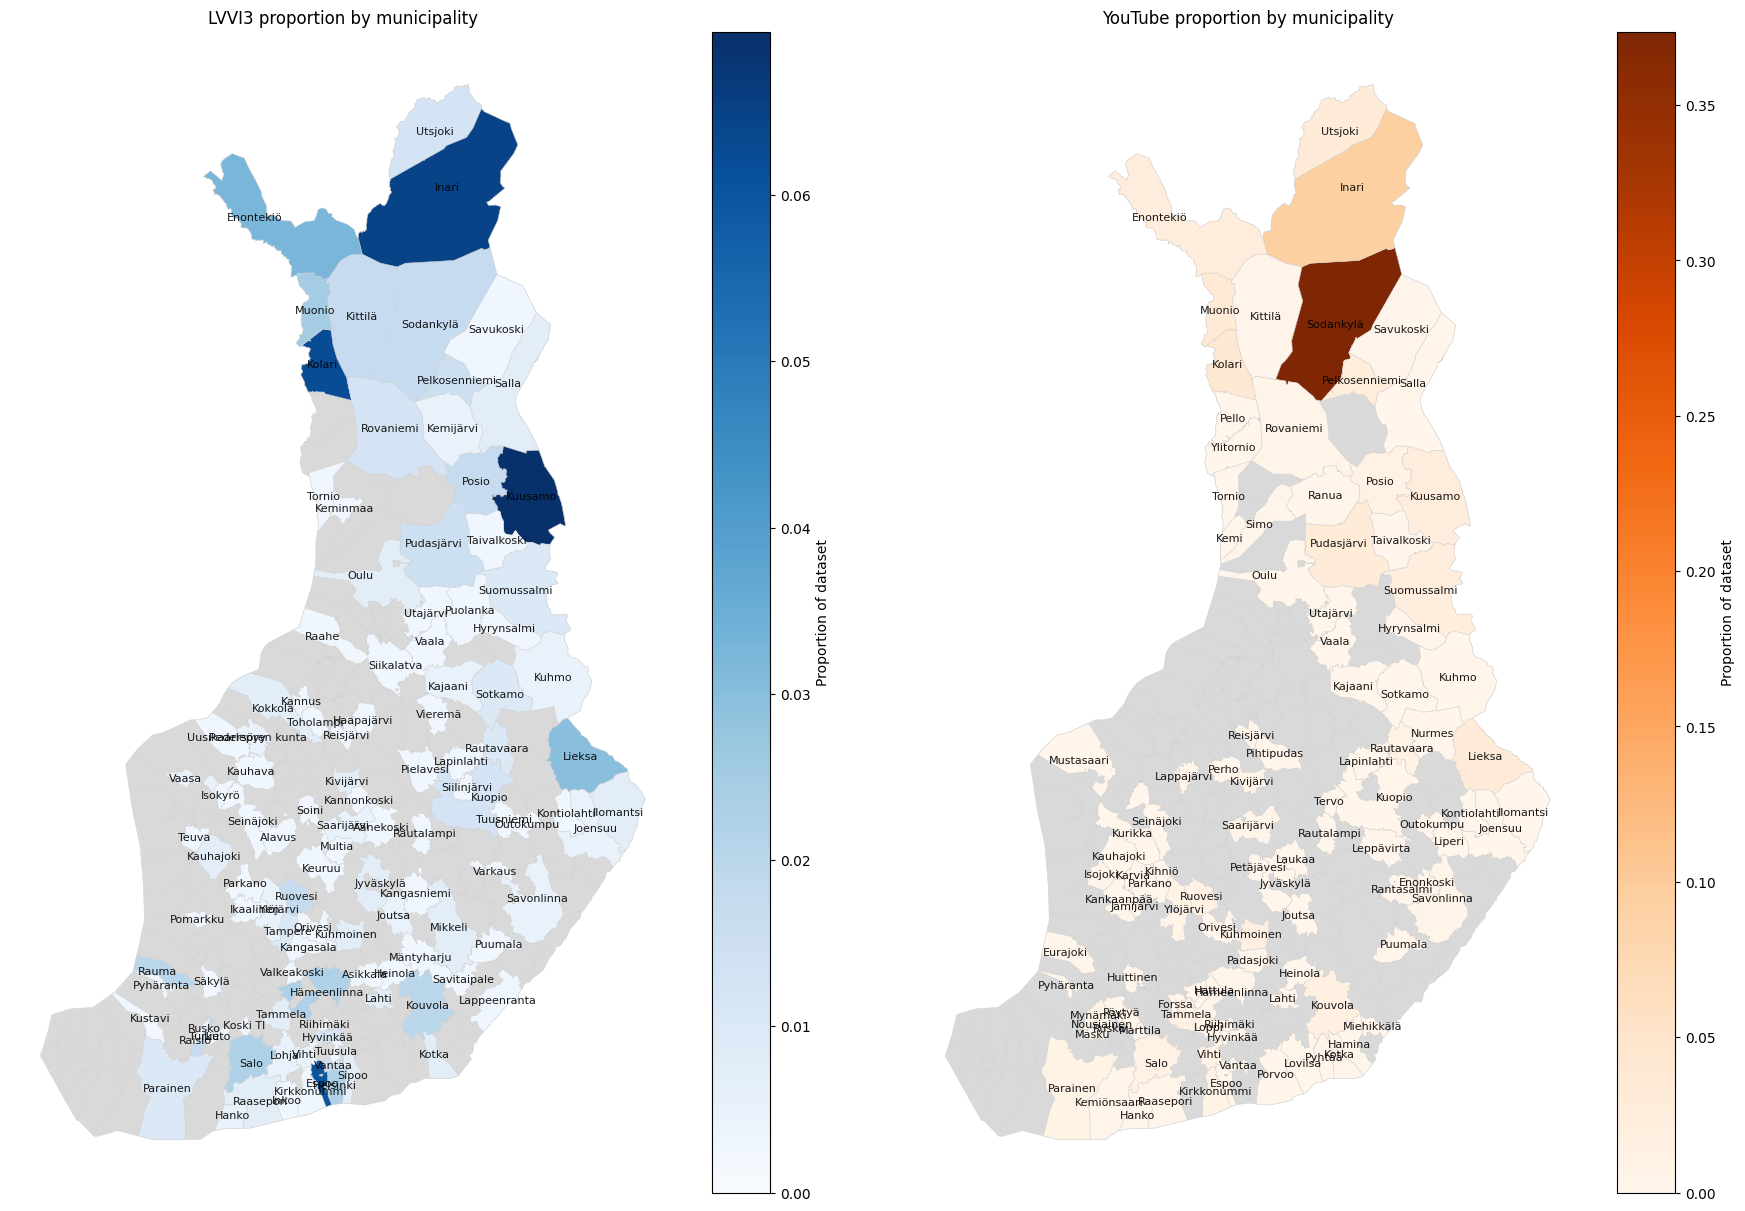

In [60]:
municipality_boundaries = read_geofile(
    '../../data/boundaries/SuomenHallinnollisetKuntajakopohjaisetAluejaot_2026_10k.gpkg',
    layer='Kunta',
)
municipality_boundaries = municipality_boundaries[['namefin', 'geometry']].rename(columns={'namefin': 'municipality'})
municipality_boundaries['municipality'] = municipality_boundaries['municipality'].astype('string').str.strip()
municipality_boundaries['label_point'] = municipality_boundaries.representative_point()

lvvi3_municipality_counts = (
    df_lvvi3[['municipality']]
    .dropna(subset=['municipality'])
    .assign(municipality=lambda df: df['municipality'].astype('string').str.strip())
    .groupby('municipality')
    .size()
    .rename('count')
    .reset_index()
)
lvvi3_total = lvvi3_municipality_counts['count'].sum()
lvvi3_municipality_counts['proportion'] = lvvi3_municipality_counts['count'] / lvvi3_total

youtube_municipality_counts = (
    df_youtube_cleaned[['video_id', 'municipality']]
    .dropna(subset=['municipality'])
    .drop_duplicates(subset=['video_id'])
    .assign(municipality=lambda df: df['municipality'].astype('string').str.strip())
    .groupby('municipality')
    .size()
    .rename('count')
    .reset_index()
)
youtube_total = youtube_municipality_counts['count'].sum()
youtube_municipality_counts['proportion'] = youtube_municipality_counts['count'] / youtube_total

lvvi3_municipality_map = municipality_boundaries.merge(
    lvvi3_municipality_counts,
    on='municipality',
    how='left',
)
youtube_municipality_map = municipality_boundaries.merge(
    youtube_municipality_counts,
    on='municipality',
    how='left',
)

for gdf_map in [lvvi3_municipality_map, youtube_municipality_map]:
    gdf_map['count'] = gdf_map['count'].fillna(0)
    gdf_map['proportion'] = gdf_map['proportion'].fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(18, 12), constrained_layout=True)
map_specs = [
    (axes[0], lvvi3_municipality_map, 'Blues', 'LVVI3 proportion by municipality'),
    (axes[1], youtube_municipality_map, 'Oranges', 'YouTube proportion by municipality'),
]

for ax, gdf_map, cmap, title in map_specs:
    gdf_map.plot(
        color='#d9d9d9',
        linewidth=0.35,
        edgecolor='lightgrey',
        ax=ax,
    )

    gdf_map[gdf_map['count'] > 0].plot(
        column='proportion',
        cmap=cmap,
        linewidth=0.35,
        edgecolor='lightgrey',
        legend=True,
        ax=ax,
        vmin=0,
        legend_kwds={'label': 'Proportion of dataset'},
    )

    for row in gdf_map[gdf_map['count'] > 0].itertuples():
        ax.text(
            row.label_point.x,
            row.label_point.y,
            row.municipality,
            fontsize=8,
            color='black',
            ha='center',
            va='center',
            alpha=0.9,
        )

    ax.set_title(title)
    ax.set_axis_off()

plt.show()

,municipality,survey_share,youtube_share,representation_ratio,representation_status
125,Hyrynsalmi,0.002494,0.002488,0.997512,Survey overrepresented
244,Savonlinna,0.004988,0.004478,0.897761,Survey overrepresented
184,Kouvola,0.019950,0.017413,0.872823,Survey overrepresented
0,Parainen,0.009975,0.007960,0.798010,Survey overrepresented
119,Rusko,0.002494,0.001990,0.798010,Survey overrepresented
...,...,...,...,...,...
294,Inari,0.064838,0.094527,1.457903,YouTube overrepresented
29,Muonio,0.024938,0.036318,1.456368,YouTube overrepresented
227,Savukoski,0.002494,0.003483,1.396517,YouTube overrepresented
242,Rautavaara,0.009975,0.010945,1.097264,YouTube overrepresented


representation_status
Survey overrepresented     99
YouTube overrepresented    55
Name: count, dtype: int64


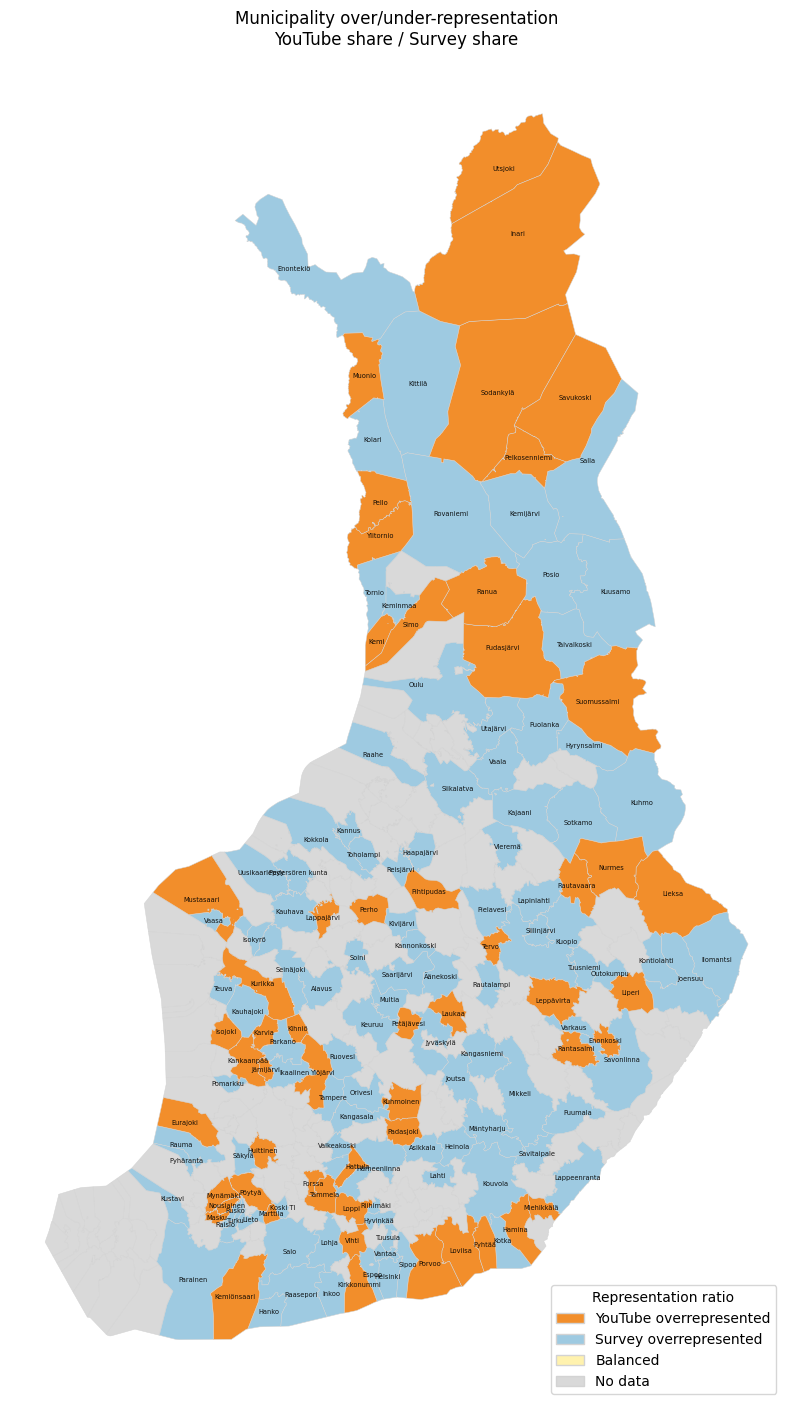

In [80]:
from matplotlib.patches import Patch

municipality_representation = municipality_boundaries[[
    'municipality',
    'geometry',
    'label_point',
]].copy()
municipality_representation = municipality_representation.merge(
    lvvi3_municipality_counts[['municipality', 'proportion']].rename(columns={'proportion': 'survey_share'}),
    on='municipality',
    how='left',
)
municipality_representation = municipality_representation.merge(
    youtube_municipality_counts[['municipality', 'proportion']].rename(columns={'proportion': 'youtube_share'}),
    on='municipality',
    how='left',
)
municipality_representation[['survey_share', 'youtube_share']] = municipality_representation[[
    'survey_share',
    'youtube_share',
]].fillna(0)

municipality_representation['representation_ratio'] = np.where(
    municipality_representation['survey_share'] > 0,
    municipality_representation['youtube_share'] / municipality_representation['survey_share'],
    np.where(municipality_representation['youtube_share'] > 0, np.inf, np.nan),
)

municipality_representation['representation_status'] = 'No data'
municipality_representation.loc[
    (municipality_representation['youtube_share'] > 0) & (municipality_representation['survey_share'] == 0),
    'representation_status',
] = 'YouTube overrepresented'
municipality_representation.loc[
    (municipality_representation['youtube_share'] == 0) & (municipality_representation['survey_share'] > 0),
    'representation_status',
] = 'Survey overrepresented'
municipality_representation.loc[
    (municipality_representation['youtube_share'] > 0)
    & (municipality_representation['survey_share'] > 0)
    & (municipality_representation['representation_ratio'] > 1),
    'representation_status',
] = 'YouTube overrepresented'
municipality_representation.loc[
    (municipality_representation['youtube_share'] > 0)
    & (municipality_representation['survey_share'] > 0)
    & (municipality_representation['representation_ratio'] < 1),
    'representation_status',
] = 'Survey overrepresented'
municipality_representation.loc[
    (municipality_representation['youtube_share'] > 0)
    & (municipality_representation['survey_share'] > 0)
    & np.isclose(municipality_representation['representation_ratio'], 1),
    'representation_status',
] = 'Balanced'

ratio_table = municipality_representation[[
    'municipality',
    'survey_share',
    'youtube_share',
    'representation_ratio',
    'representation_status',
]].copy()
ratio_table = ratio_table[ratio_table['representation_status'] != 'No data'].sort_values(
    by=['representation_status', 'representation_ratio'],
    ascending=[True, False],
)

display(ratio_table)
print(ratio_table['representation_status'].value_counts())

status_colors = {
    'YouTube overrepresented': '#f28e2b',
    'Survey overrepresented': '#9ecae1',
    'Balanced': '#fff2ae',
    'No data': '#d9d9d9',
}
status_order = [
    'YouTube overrepresented',
    'Survey overrepresented',
    'Balanced',
    'No data',
]

fig, ax = plt.subplots(figsize=(10, 14), constrained_layout=True)

for status in status_order[::-1]:
    status_gdf = municipality_representation[
        municipality_representation['representation_status'] == status
    ]
    if status_gdf.empty:
        continue

    status_gdf.plot(
        color=status_colors[status],
        linewidth=0.35,
        edgecolor='lightgrey',
        ax=ax,
    )

for row in municipality_representation[
    municipality_representation['representation_status'] != 'No data'
].itertuples():
    ax.text(
        row.label_point.x,
        row.label_point.y,
        row.municipality,
        fontsize=4.8,
        color='black',
        ha='center',
        va='center',
        alpha=0.9,
    )

legend_handles = [
    Patch(facecolor=status_colors[status], edgecolor='lightgrey', label=status)
    for status in status_order
]
ax.legend(handles=legend_handles, title='Representation ratio', loc='lower right')
ax.set_title('Municipality over/under-representation\nYouTube share / Survey share')
ax.set_axis_off()

plt.show()

In [79]:
from scipy.stats import spearmanr

municipality_rank_compare = municipality_boundaries[['municipality']].copy()
municipality_rank_compare = municipality_rank_compare.merge(
    lvvi3_municipality_counts[['municipality', 'count', 'proportion']].rename(
        columns={'count': 'survey_count', 'proportion': 'survey_share'}
    ),
    on='municipality',
    how='left',
)
municipality_rank_compare = municipality_rank_compare.merge(
    youtube_municipality_counts[['municipality', 'count', 'proportion']].rename(
        columns={'count': 'youtube_count', 'proportion': 'youtube_share'}
    ),
    on='municipality',
    how='left',
)
municipality_rank_compare[['survey_count', 'survey_share', 'youtube_count', 'youtube_share']] = (
    municipality_rank_compare[['survey_count', 'survey_share', 'youtube_count', 'youtube_share']].fillna(0)
)

municipality_rank_compare = municipality_rank_compare[
    (municipality_rank_compare['survey_count'] > 0) | (municipality_rank_compare['youtube_count'] > 0)
].copy()

municipality_rank_compare['survey_rank'] = municipality_rank_compare['survey_share'].rank(
    ascending=False,
    method='average',
)
municipality_rank_compare['youtube_rank'] = municipality_rank_compare['youtube_share'].rank(
    ascending=False,
    method='average',
)

spearman_stat, spearman_p = spearmanr(
    municipality_rank_compare['survey_rank'],
    municipality_rank_compare['youtube_rank'],
)

municipality_rank_correlation = pd.DataFrame(
    [
        {
            'analysis': 'Spearman correlation of municipality rank',
            'variables': 'Survey municipality rank vs YouTube municipality rank',
            'sample_size': len(municipality_rank_compare),
            'rho': spearman_stat,
            'p_value': spearman_p,
        }
    ]
)
municipality_rank_correlation['rho'] = municipality_rank_correlation['rho'].map(lambda value: f'{value:.3f}')
municipality_rank_correlation['p_value'] = municipality_rank_correlation['p_value'].map(lambda value: f'{value:.4g}')

print('Municipality rank correlation between the survey and YouTube datasets')
display(municipality_rank_correlation)

municipality_rank_compare = municipality_rank_compare.sort_values('survey_rank')
display(
    municipality_rank_compare[[
        'municipality',
        'survey_count',
        'youtube_count',
        'survey_share',
        'youtube_share',
        'survey_rank',
        'youtube_rank',
    ]].head(20)
)

Municipality rank correlation between the survey and YouTube datasets


,analysis,variables,sample_size,rho,p_value
0,Spearman correlation of municipality rank,Survey municipality rank vs YouTube municipali...,154,0.248,0.001928


,municipality,survey_count,youtube_count,survey_share,youtube_share,survey_rank,youtube_rank
87,Kuusamo,28.0,48.0,0.069825,0.023881,1.0,10.0
294,Inari,26.0,190.0,0.064838,0.094527,2.0,2.0
18,Kolari,25.0,85.0,0.062344,0.042289,3.0,3.0
300,Espoo,24.0,1.0,0.059850,0.000498,4.0,87.5
23,Enontekiö,13.0,49.0,0.032419,0.024378,5.0,9.0
203,Lieksa,12.0,65.0,0.029925,0.032338,6.0,5.0
29,Muonio,10.0,73.0,0.024938,0.036318,7.0,4.0
116,Helsinki,9.0,0.0,0.022444,0.000000,9.0,130.0
173,Salo,9.0,28.0,0.022444,0.013930,9.0,14.0
12,Hämeenlinna,9.0,6.0,0.022444,0.002985,9.0,36.5
